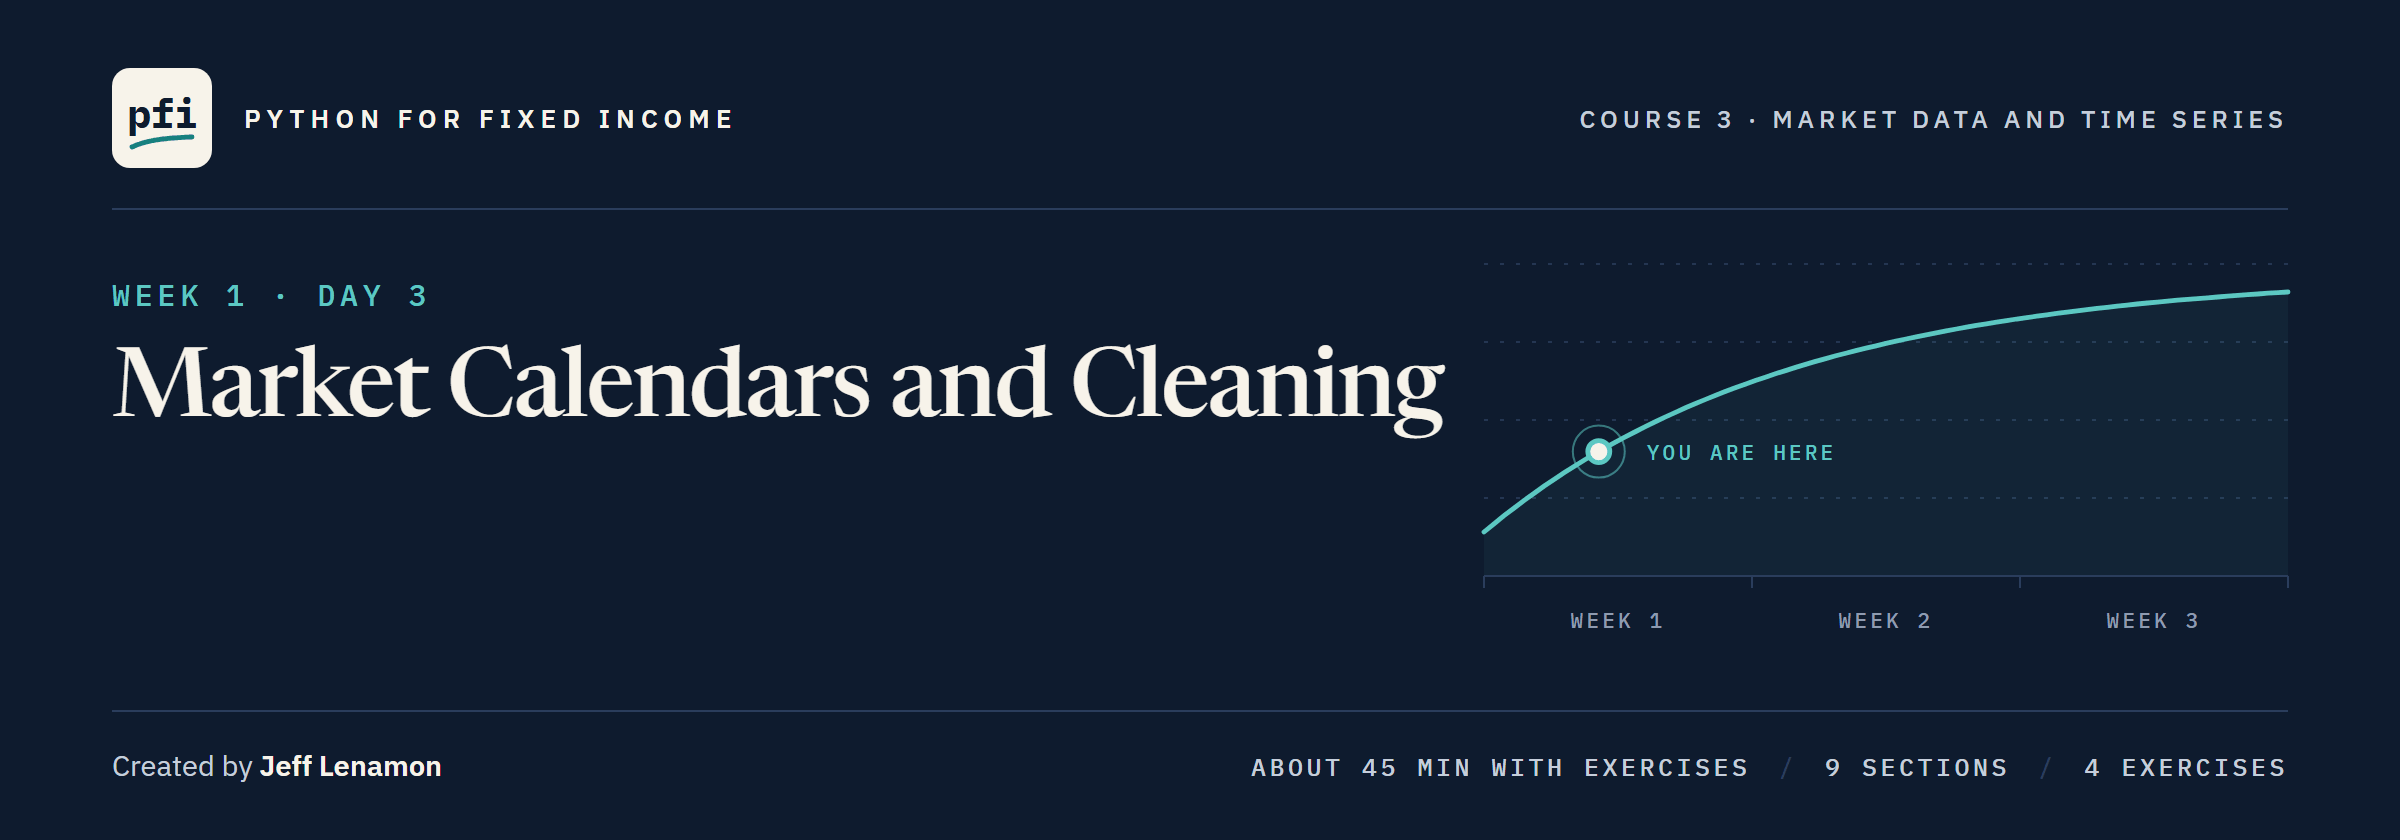

# Market Calendars and Cleaning

Week 1, Day 3. The market's days are the dates the Treasury file has: the weekdays it skips, a holiday calendar that disagrees with it, FRED's dots on the same days, series joined without inventing a day, forward fill kept for display, and values that stopped moving.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day3/03_market_calendars_and_cleaning.ipynb)

### The Desk Lead's Note

> Before anyone takes a change, a window or a join on our curve, I need to know which days the market had. Put the weekdays our Treasury file skips in a function, and give Excel the same list. Everyone downloads a holiday calendar: tell me whether it agrees with the file. Check that FRED's dots fall on those same days. Then put series side by side without inventing a day, show me what forward fill does to a change, and find any value that stopped updating. Three tested functions, committed under a message we can search for.

Every cell runs without a key, and the saved outputs are that run.
The spreads are synthetic, in bp.

**The market's days are the dates the file has: no holiday list decides them.**

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}course03_market_data/start_of_day/start_day.py
from start_day import start_day

# a new work folder: the data files, Course 2's bondmath.py, and marketdata.py, its tests,
# and their Git history as notebook 02 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(3)

Work folder pfi_course3_03_k4w7q2xr: 4 data files, Course 2's bondmath.py, marketdata.py as notebook 02 left it, 2 commits


`start_day(3)` copied in the Treasury file, the synthetic spreads, FRED's 10-year sample, and notebook 02's module.

### The Tests Pass Before We Start

In [2]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.........                                                                [100%]
9 passed in 0.50s



### Imports and the Two Files

In [3]:
import importlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import marketdata as md

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])

In [4]:
# the Treasury file as in notebook 02; the synthetic spreads, in bp, the same way
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
print(len(treasury), 'and', len(spreads), 'rows; the same dates:',
      treasury.index.equals(spreads.index))
print(list(spreads.columns))

2940 and 2940 rows; the same dates: True
['ig_spread_bp', 'hy_spread_bp']


## Your Route Through Day 3

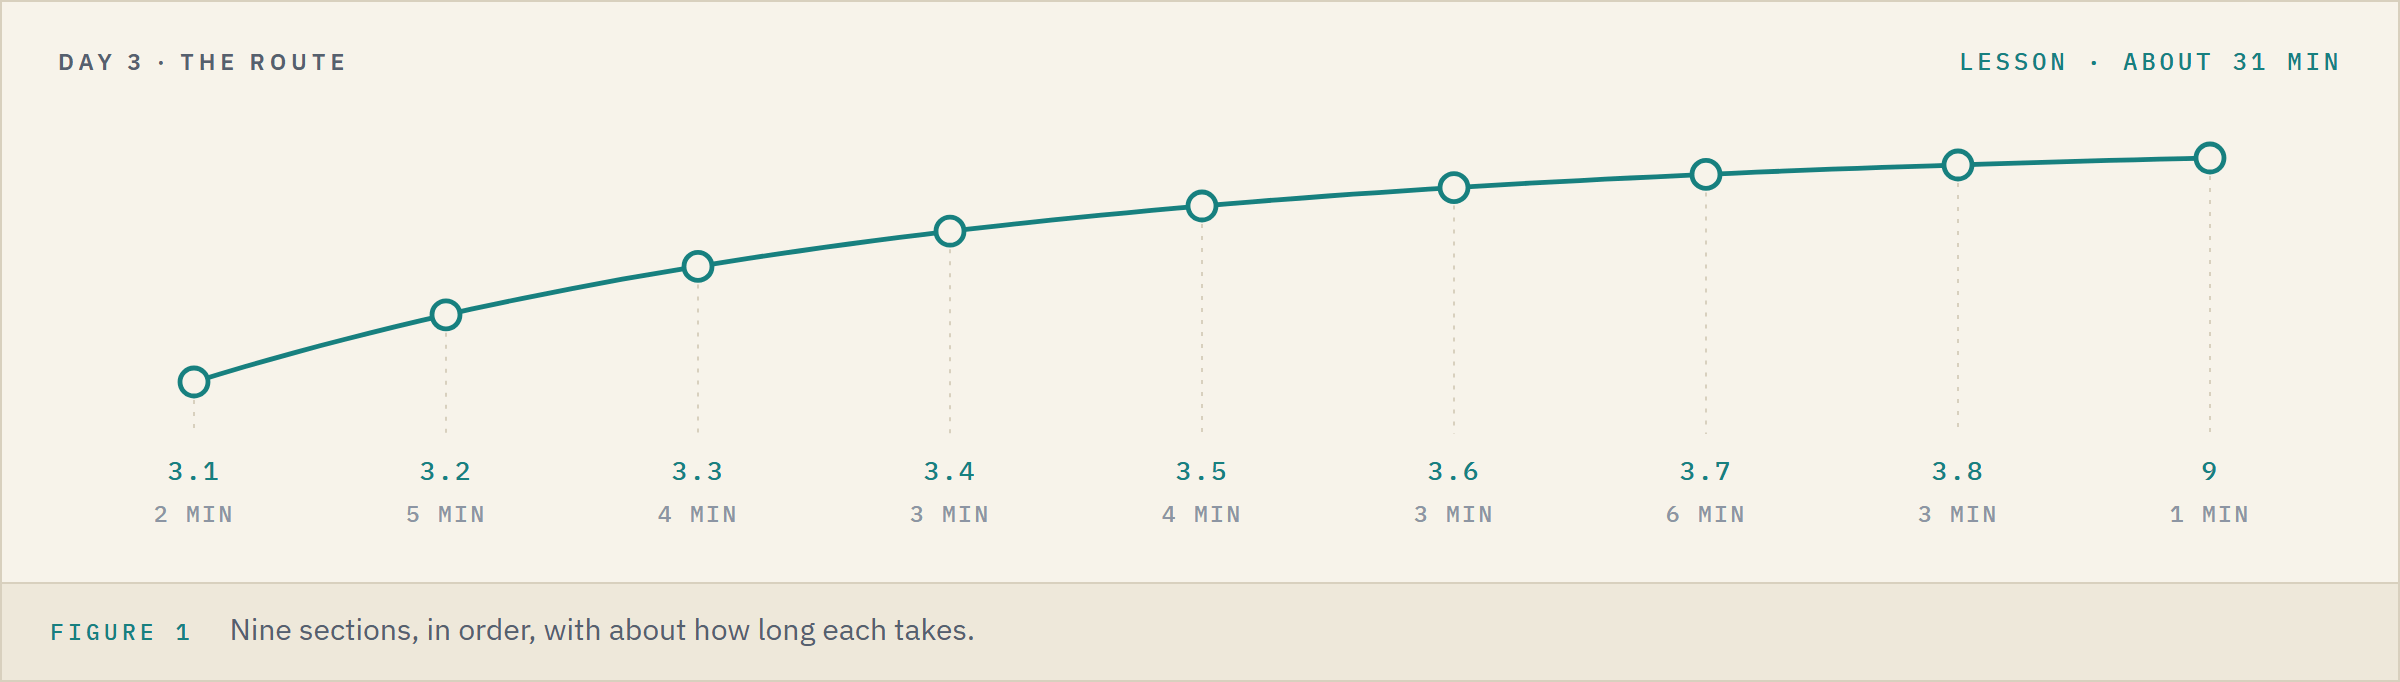

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">3.1</td><td align="left">Three Kinds of Day</td><td align="left">2 min</td></tr>
<tr><td align="left">3.2</td><td align="left">The File as Its Own Calendar: <code>missing_weekdays</code></td><td align="left">5 min</td></tr>
<tr><td align="left">3.3</td><td align="left">A Holiday Calendar Is Not the Market Calendar</td><td align="left">4 min</td></tr>
<tr><td align="left">3.4</td><td align="left">FRED's Dots Are the Same Days</td><td align="left">3 min</td></tr>
<tr><td align="left">3.5</td><td align="left">Joining Two Series: <code>align</code></td><td align="left">4 min</td></tr>
<tr><td align="left">3.6</td><td align="left">Forward Fill, for Display Only</td><td align="left">3 min</td></tr>
<tr><td align="left">3.7</td><td align="left">Stale Values: <code>stale_runs</code></td><td align="left">6 min</td></tr>
<tr><td align="left">3.8</td><td align="left">Fix the Message Before Anything Builds on It</td><td align="left">3 min</td></tr>
<tr><td align="left">9</td><td align="left">Bring It Home</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 31 minutes for the lesson, then about 12 for the four exercises.

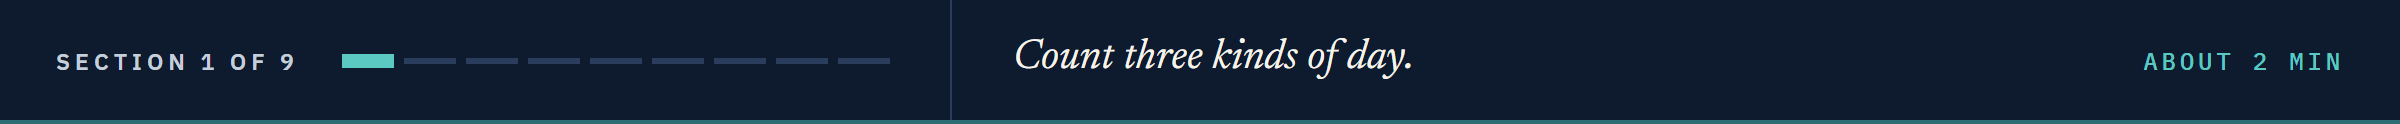

## 3.1 Three Kinds of Day

Notebook 02 left the 10-year with no row on Labor Day.
Course 1's Treasury Yields case study counted such weekdays once, with `date_range(freq='B')` and `.difference`.
Today the count becomes a calendar.

### Three Counts

In [5]:
# the file's first and last dates; every calendar day between, then Monday to Friday
first, last = treasury.index[0], treasury.index[-1]
# bdate_range is Course 1's date_range(freq='B') as its own function
calendar_days = pd.date_range(first, last)
weekdays = pd.bdate_range(first, last)
market_days = treasury.index
print(f'{first.date()} to {last.date()}: {len(calendar_days):,} calendar days,',
      f'{len(weekdays):,} weekdays, {len(market_days):,} market days')

2015-01-02 to 2026-10-02: 4,292 calendar days, 3,066 weekdays, 2,940 market days


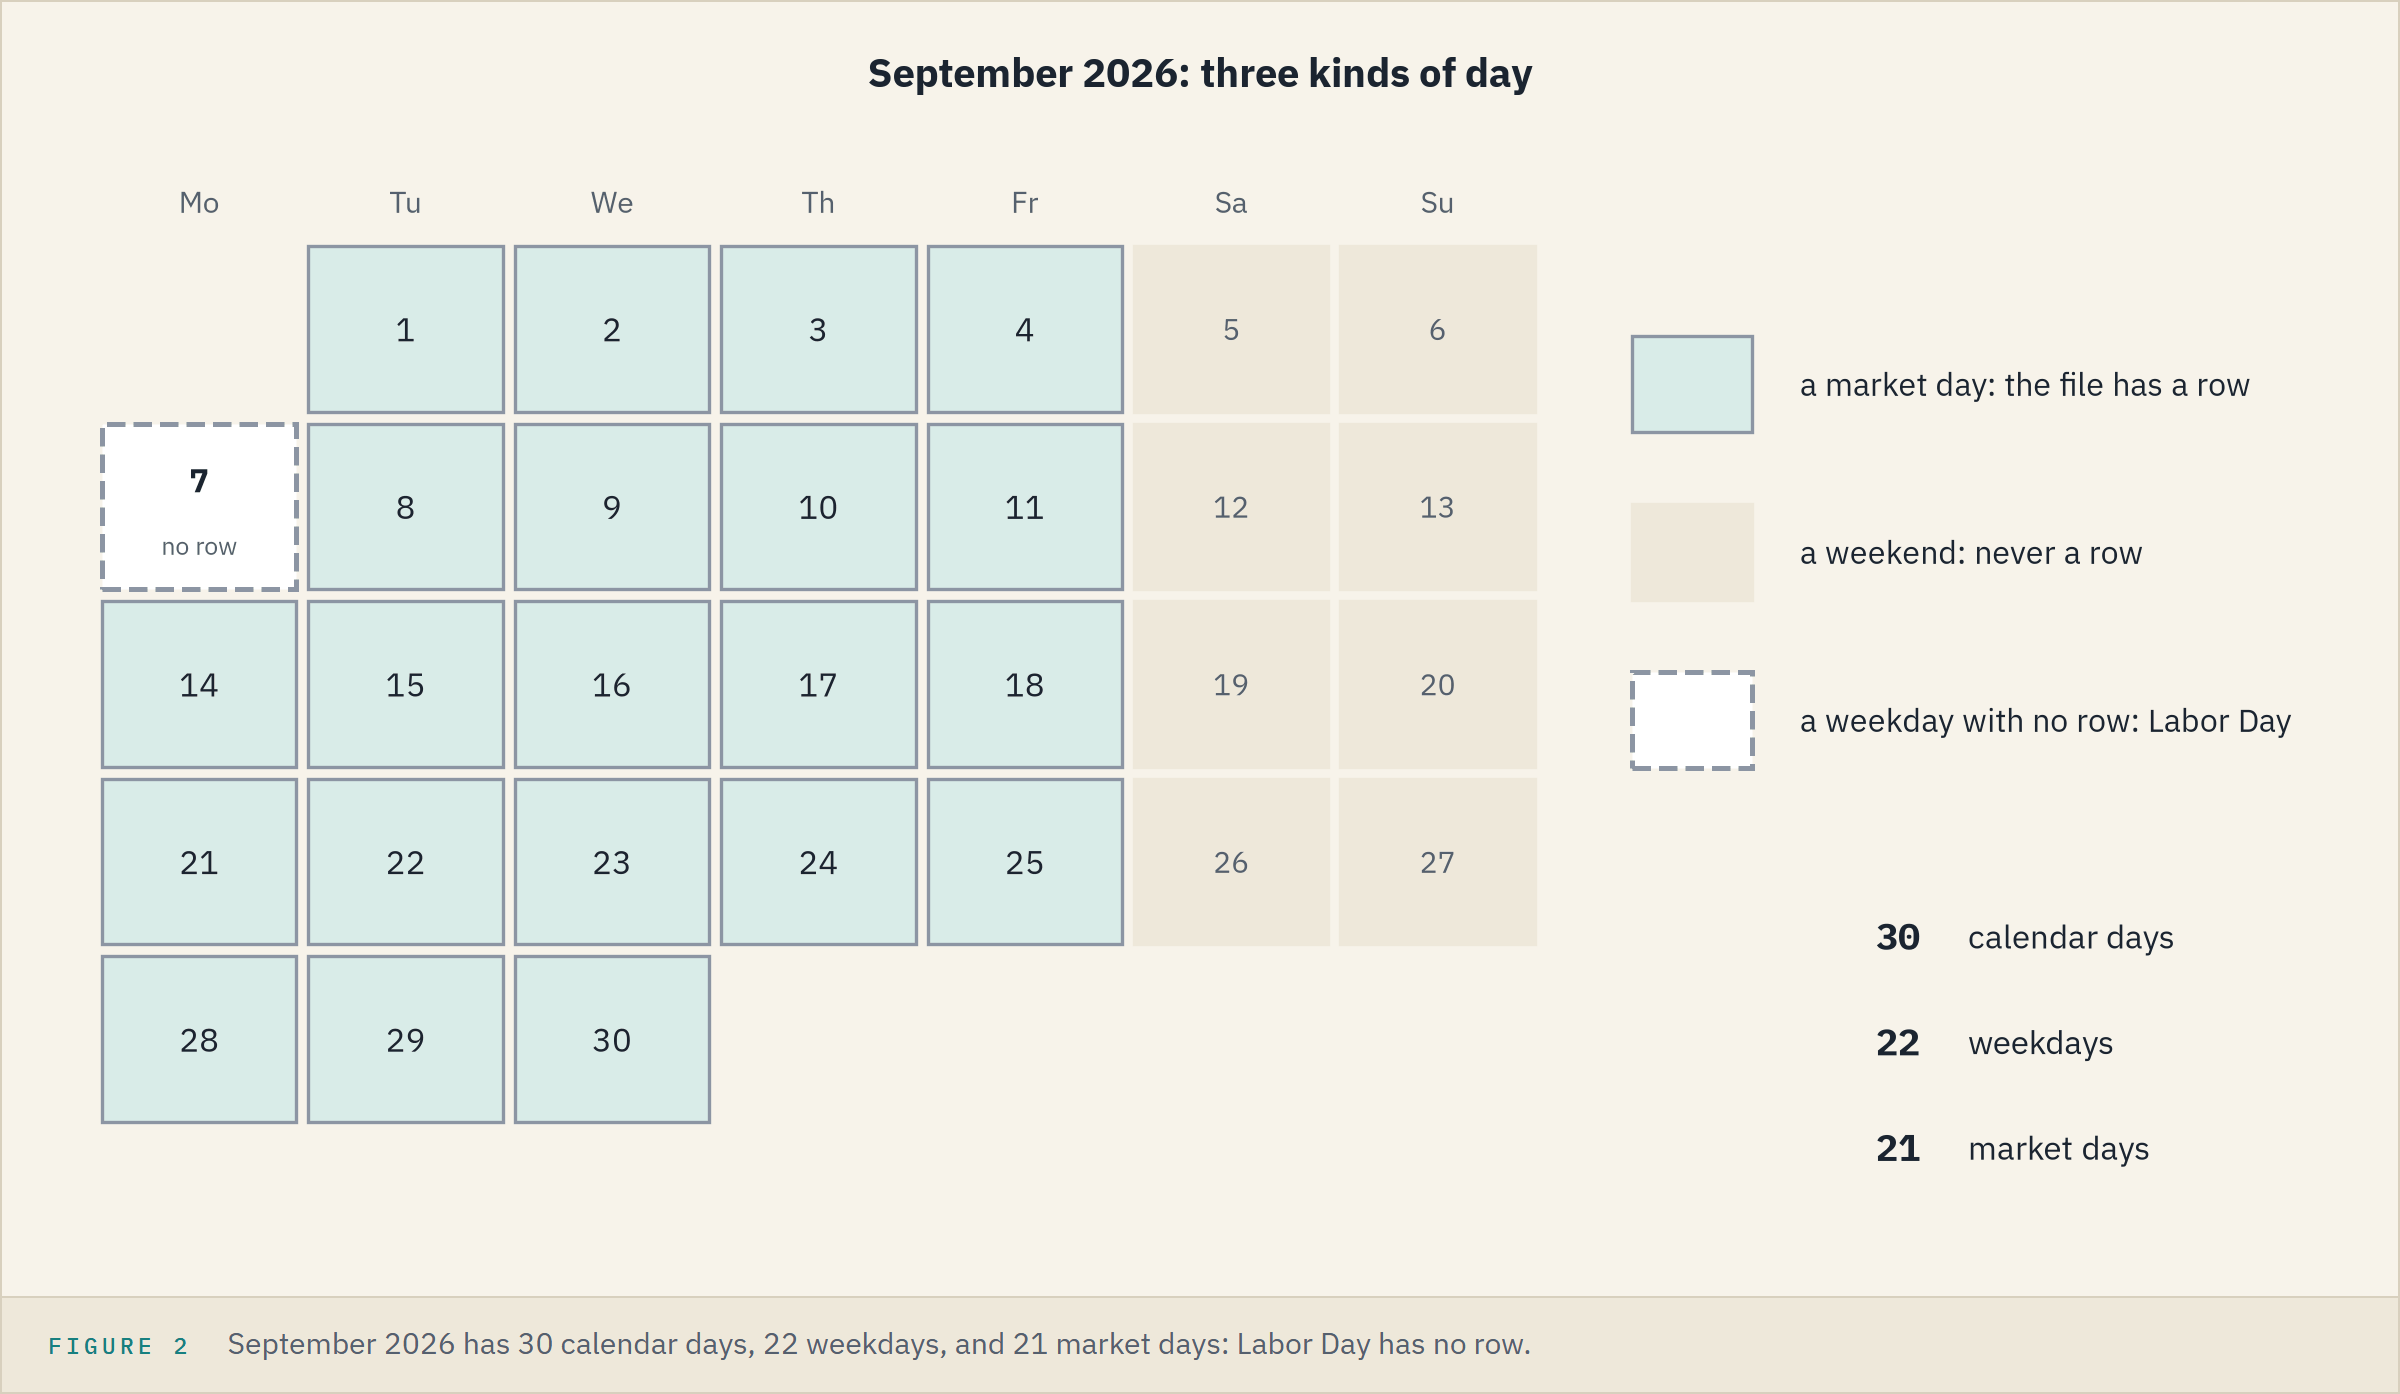

A **market day** is a date the file has.

**Excel side by side.** Dates in A2:A2941; the 10 Yr in B, `ig_spread_bp` in C.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Calendar days</td><td align="left"><code>len(pd.date_range(first, last))</code></td><td align="left"><code>=A2941-A2+1</code></td><td align="left">4,292</td></tr>
<tr><td align="left">Weekdays</td><td align="left"><code>len(pd.bdate_range(first, last))</code></td><td align="left"><code>=NETWORKDAYS(A2,A2941)</code></td><td align="left">3,066</td></tr>
<tr><td align="left">Market days</td><td align="left"><code>len(treasury.index)</code></td><td align="left"><code>=COUNT(A2:A2941)</code></td><td align="left">2,940</td></tr>
</table>
<br clear="left">

**Calendar days, weekdays, market days: every calculation in this course runs on the third.**

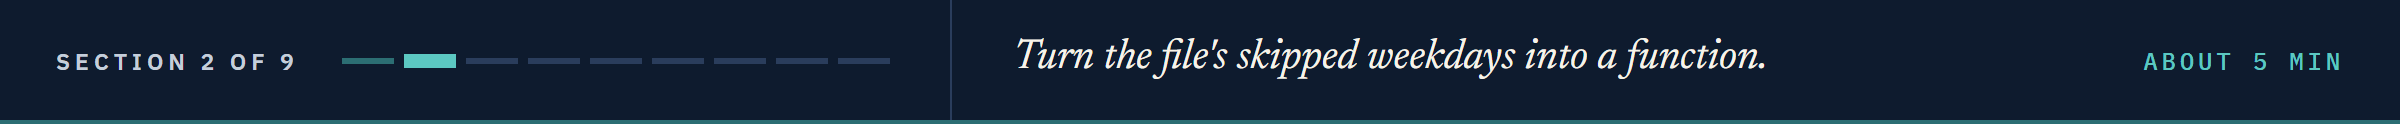

## 3.2 The File as Its Own Calendar: `missing_weekdays`

Every later notebook asks which weekdays the file skips, so it becomes a function.

### Append It, Docstring First

Read both docstrings first.
`_check_index` stops on an index that is not unique dates in ascending order; its leading underscore marks a helper inside the module.
`pd.Index` and `-> None` read as notebook 02's `str | None` did: what goes in, and what comes back, here nothing.

In [6]:
%%writefile -a marketdata.py


def _check_index(index: pd.Index, what: str) -> None:
    """Stop unless `index` is a DatetimeIndex with unique dates in ascending order.

    A helper for the functions below (the leading underscore marks it as not part of the module's API).
    """
    if not isinstance(index, pd.DatetimeIndex):
        raise ValueError(f"{what} must have a DatetimeIndex, not {type(index).__name__}")
    if not index.is_unique:
        raise ValueError(f"{what} has repeated dates, for example {index[index.duplicated()][0].date()}")
    if not index.is_monotonic_increasing:
        raise ValueError(f"{what} dates are not in ascending order")


def missing_weekdays(index: pd.DatetimeIndex) -> pd.DatetimeIndex:
    """The weekdays from the first date to the last that have no row.

    Units: dates. Convention: a weekday is Monday to Friday; no holiday calendar is used, so the result is
    every weekday the data skipped (holidays and any other closure). Weekends are never counted.
    Raises ValueError on an index that is not unique and ascending dates.
    """
    _check_index(index, "index")
    # every Monday to Friday in the span
    weekdays = pd.bdate_range(index[0], index[-1])
    # the ones with no row
    missing = weekdays.difference(index)
    missing.name = "date"
    return missing

Appending to marketdata.py


### 126, as Dates

In [7]:
# read the file again, so md holds missing_weekdays
importlib.reload(md)
missing = md.missing_weekdays(treasury.index)
print(len(missing), 'weekdays with no row, from', missing[0].date(), 'to', missing[-1].date())

126 weekdays with no row, from 2015-01-19 to 2026-09-07


**Excel side by side.** `=NETWORKDAYS(A2,A2941)-COUNT(A2:A2941)` returns 126.

### The Seven of 2026

In [8]:
# this year's missing weekdays, with the name of each day
missing_2026 = missing[missing.year == 2026]
for day in missing_2026:
    print(day.date(), day.strftime('%A'))
print(len(treasury.loc['2026']), 'rows in 2026')

2026-01-01 Thursday
2026-01-19 Monday
2026-02-16 Monday
2026-05-25 Monday
2026-06-19 Friday
2026-07-03 Friday
2026-09-07 Monday
190 rows in 2026


**Excel side by side.** H2:H8 hold the seven dates: Excel's holiday list.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Day of the week, Monday first</td><td align="left"><code>pd.Timestamp('2026-09-07').dayofweek</code>: 0</td><td align="left"><code>=WEEKDAY(DATE(2026,9,7),2)</code></td><td align="left">1</td></tr>
<tr><td align="left">Day of the week, Excel's default</td><td align="left"></td><td align="left"><code>=WEEKDAY(DATE(2026,9,7))</code></td><td align="left">2: Sunday is 1</td></tr>
<tr><td align="left">Weekdays of 2026, to 2 October</td><td align="left"><code>len(pd.bdate_range('2026-01-01', last))</code></td><td align="left"><code>=NETWORKDAYS(DATE(2026,1,1),DATE(2026,10,2))</code></td><td align="left">197</td></tr>
<tr><td align="left">Less the list</td><td align="left"><code>len(treasury.loc['2026'])</code></td><td align="left"><code>=NETWORKDAYS(DATE(2026,1,1),DATE(2026,10,2),H2:H8)</code></td><td align="left">190</td></tr>
<tr><td align="left">September, less the list</td><td align="left"><code>len(treasury.loc['2026-09'])</code></td><td align="left"><code>=NETWORKDAYS(DATE(2026,9,1),DATE(2026,9,30),H2:H8)</code></td><td align="left">21</td></tr>
</table>
<br clear="left">

pandas counts Monday as 0, Excel's `WEEKDAY(...,2)` as 1.

**Predict 1**

Q. Excel's `=WORKDAY(DATE(2026,9,4),1)` asks for the working day after Friday 4 September, with no holiday list. It returns:

A) Monday 2026-09-07
B) Tuesday 2026-09-08
C) Saturday 2026-09-05

### The Day After Friday 4 September

In [9]:
# the first weekday after Friday 4 September, then the first date the file has after it
friday = pd.Timestamp('2026-09-04')
print('Next weekday:   ', weekdays[weekdays > friday][0].date())
print('Next market day:', market_days[market_days > friday][0].date())

Next weekday:    2026-09-07
Next market day: 2026-09-08


A: `WORKDAY` skips weekends and knows no holidays unless you give it a list.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Next weekday</td><td align="left"><code>weekdays[weekdays &gt; friday][0]</code></td><td align="left"><code>=WORKDAY(DATE(2026,9,4),1)</code></td><td align="left">2026-09-07</td></tr>
<tr><td align="left">Next market day</td><td align="left"><code>market_days[market_days &gt; friday][0]</code></td><td align="left"><code>=WORKDAY(DATE(2026,9,4),1,H2:H8)</code></td><td align="left">2026-09-08</td></tr>
</table>
<br clear="left">

### The First Test

In [10]:
%%writefile -a test_marketdata.py


def test_missing_weekdays_hand_index():
    # Friday 2026-09-04 to Wednesday 2026-09-09, with Monday (Labor Day) and Tuesday absent
    index = pd.DatetimeIndex(["2026-09-04", "2026-09-09"])
    missing = md.missing_weekdays(index)
    # the weekend is never counted; the two weekdays are
    assert list(missing) == [pd.Timestamp("2026-09-07"), pd.Timestamp("2026-09-08")]

Appending to test_marketdata.py


### Run pytest

In [11]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

..........                                                               [100%]
10 passed in 0.50s



**`missing_weekdays` makes the file its own calendar: 126 dates, and as Excel's holiday list the seven of 2026 give the file's 190 rows.**

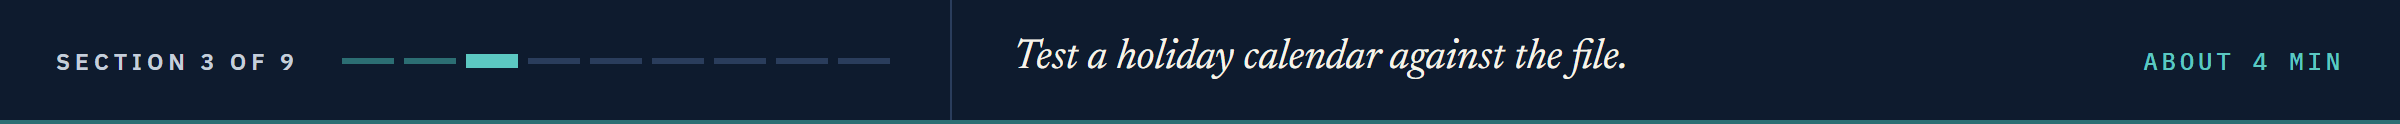

## 3.3 A Holiday Calendar Is Not the Market Calendar

Tutorials and AI answers reach for pandas' federal holiday calendar.

### pandas' Federal Holidays

In [12]:
# pandas' federal holiday calendar, and its Good Friday rule
from pandas.tseries.holiday import GoodFriday, USFederalHolidayCalendar

# return_name=True gives a Series: each holiday's name, indexed by its date
federal = USFederalHolidayCalendar().holidays(first, last, return_name=True)
print(len(federal), 'federal holidays, all on weekdays:', (federal.index.dayofweek < 5).all())

121 federal holidays, all on weekdays: True


pandas moves a Saturday holiday to the Friday before and a Sunday one to the Monday after.

**Predict 2**

Q. pandas lists 121 holidays; the file skips 126 weekdays. How many of pandas' holidays have a row in the file anyway? Write down a number.

### Compare Both Ways

In [13]:
# intersection keeps the dates in both, as in notebook 02's live cell; difference those in one only
shared = missing.intersection(federal.index)
not_federal = missing.difference(federal.index)
federal_with_rows = federal.index.difference(missing)
print(len(shared), 'in both,', len(not_federal), 'skipped but not federal,',
      len(federal_with_rows), 'federal with a row')
federal[federal_with_rows]

117 in both, 9 skipped but not federal, 4 federal with a row


2017-11-10                            Veterans Day
2021-06-18    Juneteenth National Independence Day
2021-12-31                          New Year's Day
2023-11-10                            Veterans Day
dtype: str

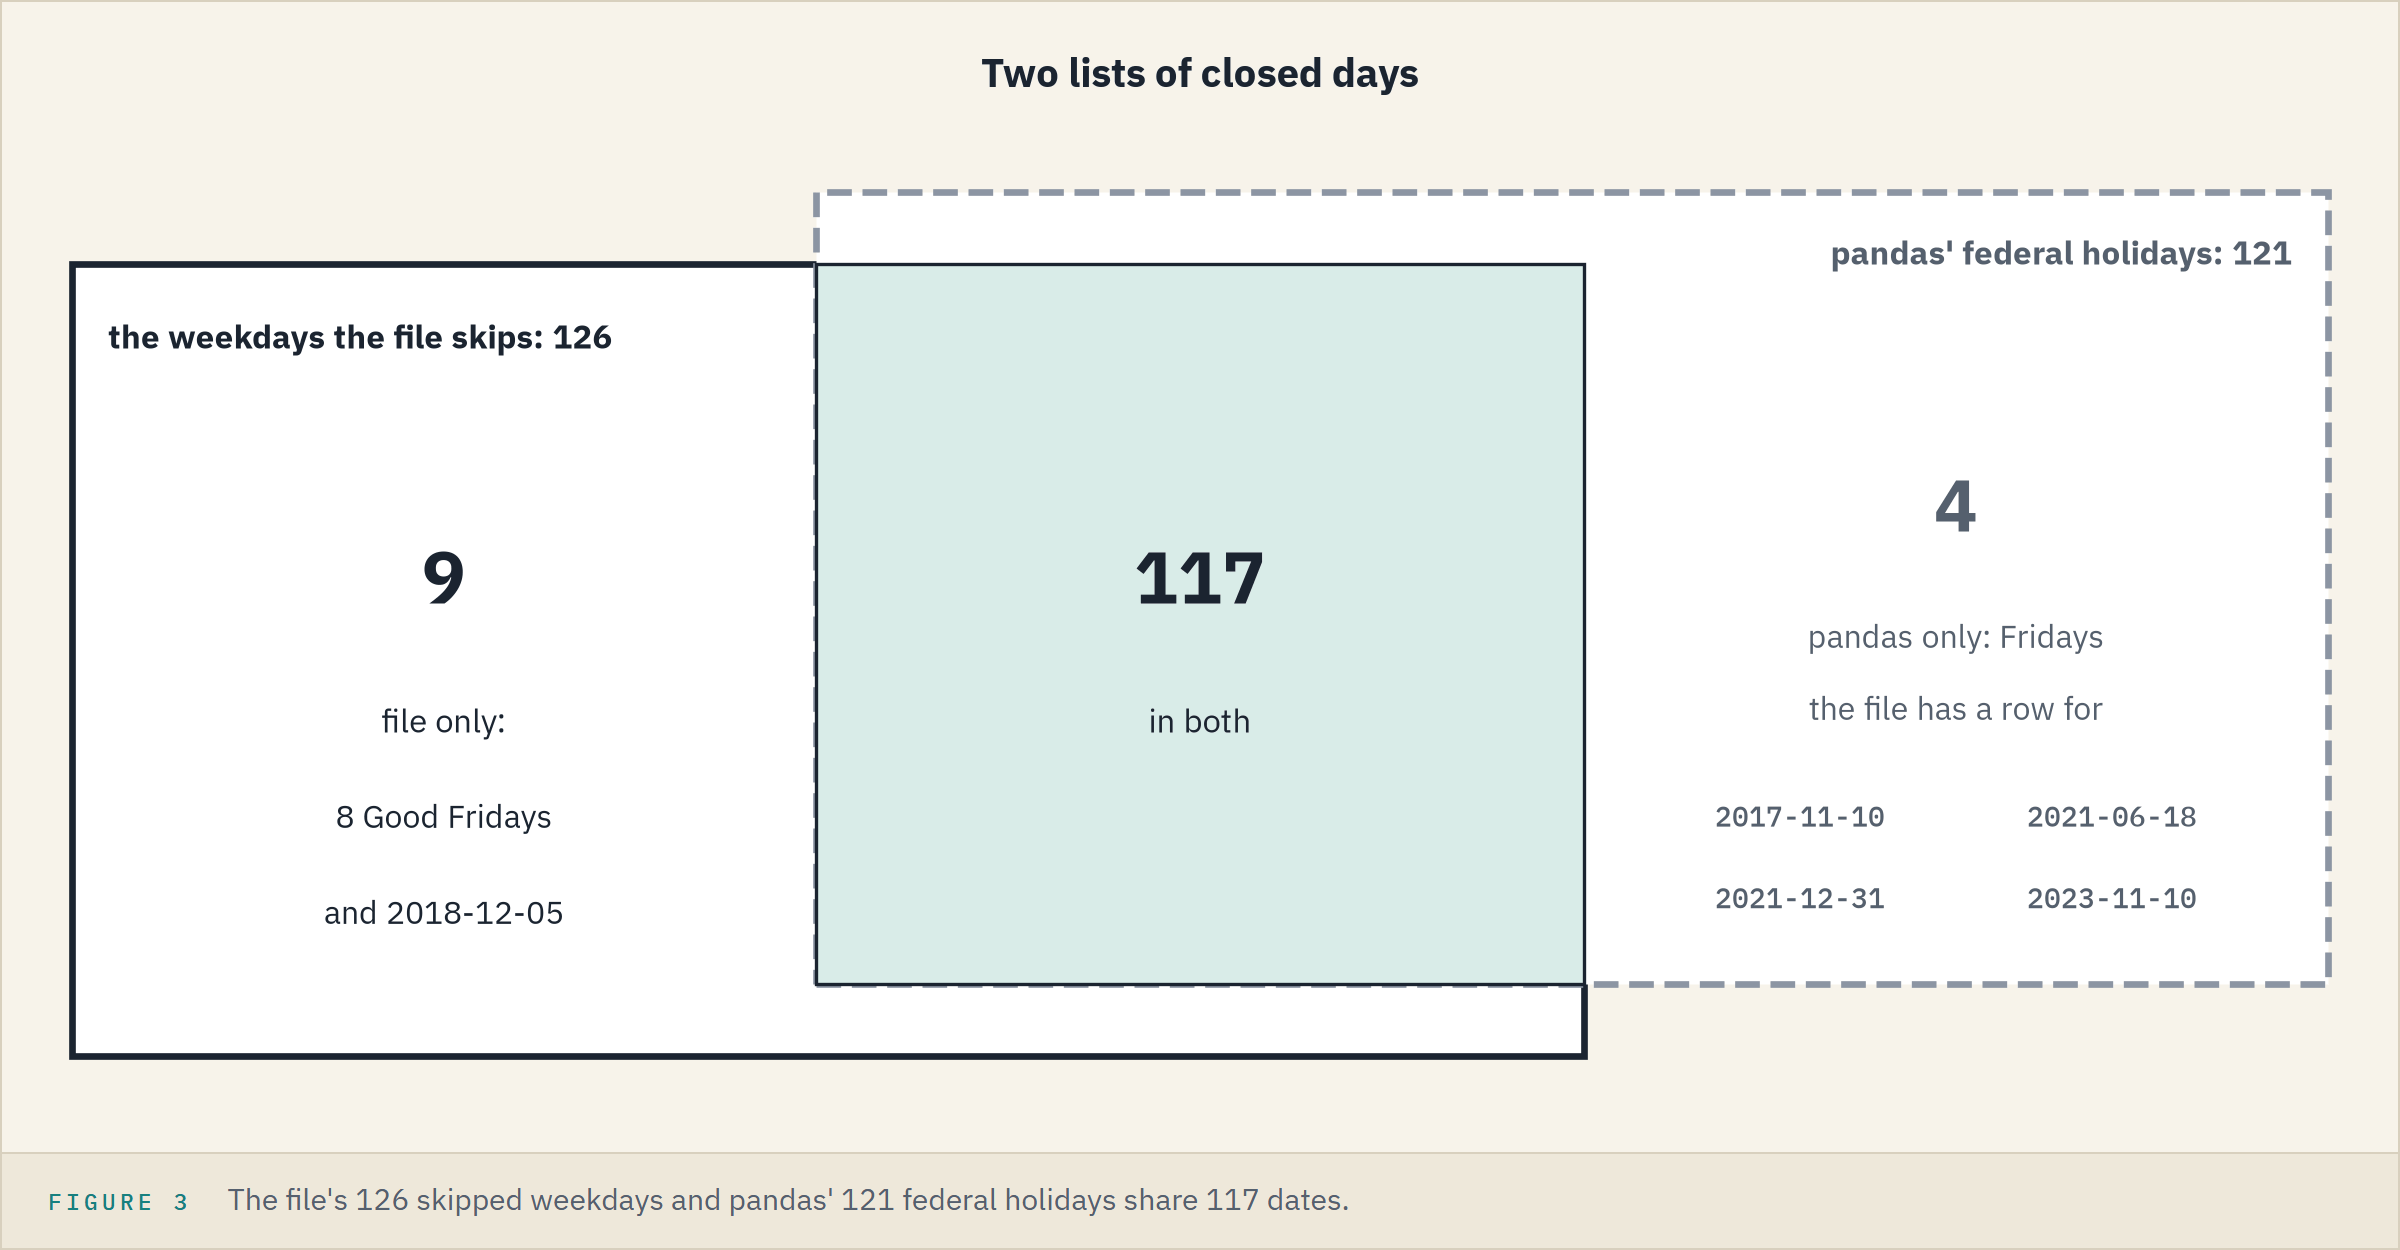

4, every one a Friday.

### Good Friday

In [14]:
# pandas' Good Friday rule: one date a year
good_fridays = GoodFriday.dates(first, last)
print(len(not_federal.intersection(good_fridays)), 'of the 9 are Good Fridays; the other:',
      list(not_federal.difference(good_fridays).strftime('%Y-%m-%d')))
print('Good Fridays the file has:',
      list(good_fridays.intersection(market_days).strftime('%Y-%m-%d')))

8 of the 9 are Good Fridays; the other: ['2018-12-05']
Good Fridays the file has: ['2015-04-03', '2021-04-02', '2023-04-07', '2026-04-03']


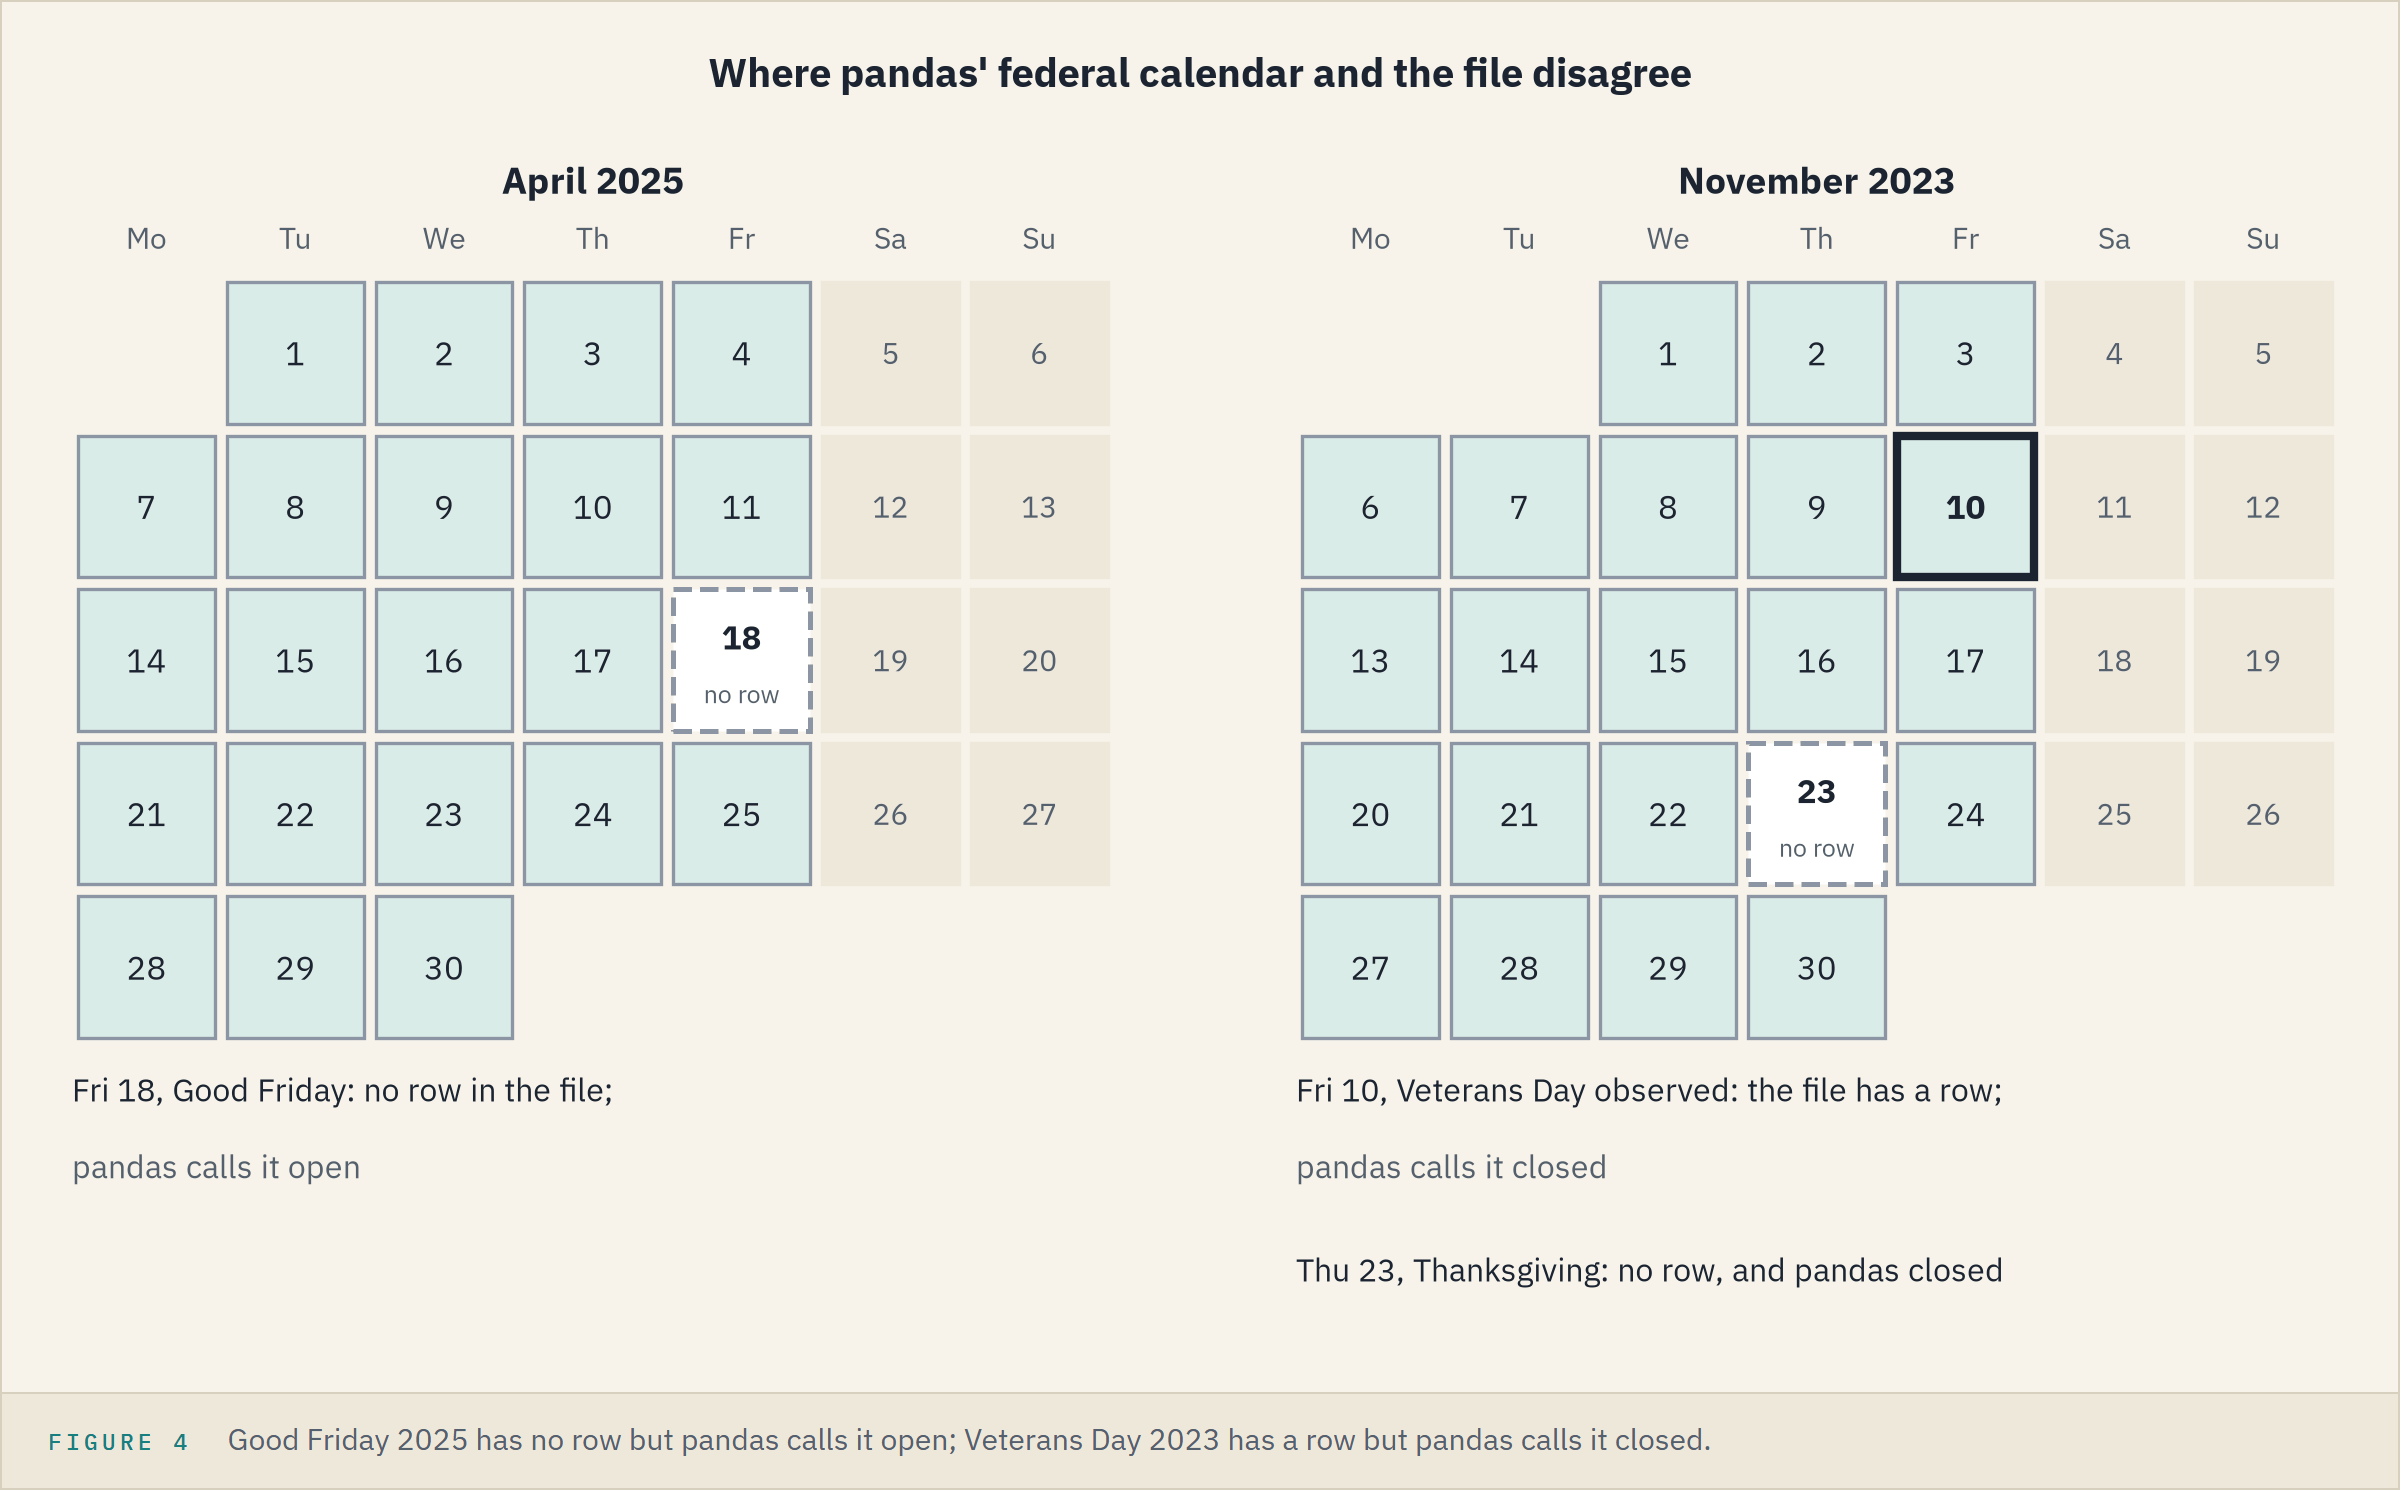

The course gives no reason for any of these days: the file is the record.

**pandas' calendar misses 9 closures and closes 4 days the market had: the calendar is the file's own dates.**

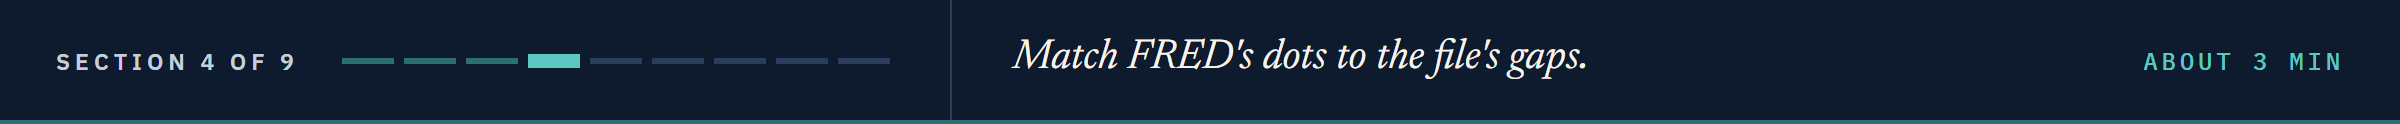

## 3.4 FRED's Dots Are the Same Days

Notebook 02 drew two ways of saying nothing: FRED's dot and the file's absent row, on Labor Day.

### The Sample's Dot

In [15]:
# notebook 02's sample, parsed: its dot is kept as NaN
payload = json.loads(Path('course3_fred_format_dgs10.json').read_text(encoding='utf-8'))
sample = md.parse_fred_observations(payload, 'DGS10')
dots = sample.index[sample.isna()]
print('Dots:', list(dots.strftime('%Y-%m-%d')),
      '| each a missing weekday:', dots.isin(missing).all())

Dots: ['2026-09-07'] | each a missing weekday: True


### The Numbers Fall on the File's Rows

In [16]:
# the file's 10 Yr over the sample's span, and the sample without its dot
file_span = treasury.loc[sample.index[0]:sample.index[-1], '10 Yr']
sample_numbers = sample.dropna()
print('Same dates:', sample_numbers.index.equals(file_span.index),
      '| largest gap:', (sample_numbers - file_span).abs().max(), 'percent')

Same dates: True | largest gap: 0.0 percent


### FRED Since 2015

With your key, the live cell asks FRED for the 10-year since 2015 and checks every dot.

*This product uses the FRED&reg; API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.*

### The Key Cell

In [17]:
from pathlib import Path

# your .env file: in my_bondmath, outside every repository. The key cell looks here last.
ENV_FILE = Path.home() / "projects" / "my_bondmath" / ".env"
# what every live cell prints when no key was found
NO_KEY_MESSAGE = "Live cell skipped: no FRED key was found. Every other cell runs without one."

In [18]:
try:
    fred_key = md.get_secret("FRED_API_KEY", env_file=ENV_FILE)
    print("FRED key: found. It is held in memory and is never printed.")
except RuntimeError as error:
    fred_key = None
    print(f"FRED key: not found. Live cells will be skipped. {error}")

FRED key: not found. Live cells will be skipped. Secret FRED_API_KEY not found. Looked in: the environment variable FRED_API_KEY, Colab's Secrets panel, and the file .env given as env_file.


### Every Dot Since 2015

In [19]:
# a live cell: it needs your key and the network
if fred_key is None:
    print(NO_KEY_MESSAGE)
else:
    live_dgs10 = md.fred_series('DGS10', fred_key, start='2015-01-01')
    # FRED can be a day ahead of the snapshot: compare up to the last date both have
    live_end = min(live_dgs10.index[-1], last)
    live_span = live_dgs10.loc[first:live_end]
    live_dots = live_span.index[live_span.isna()]
    live_expected = missing[missing <= live_end]
    assert list(live_dots) == list(live_expected), 'a dot that is not a missing weekday'
    assert (live_span.index.dayofweek < 5).all(), 'a weekend row'
    live_numbers = live_span.dropna()
    live_gap = (live_numbers - treasury.loc[:live_end, '10 Yr']).abs().max()
    assert live_numbers.index.equals(treasury.loc[:live_end].index) and live_gap <= 1e-9
    print(f'{len(live_span):,} rows, {len(live_dots)} dots, each a missing weekday;',
          f'largest gap {live_gap:.1e} percent')

Live cell skipped: no FRED key was found. Every other cell runs without one.


With your key, it prints FRED's rows since 2015, its dots, every one a weekday the file skips, and a largest gap of 0.

**FRED's dots and the file's absent rows are the same days: drop the dots and the two sources share one calendar.**

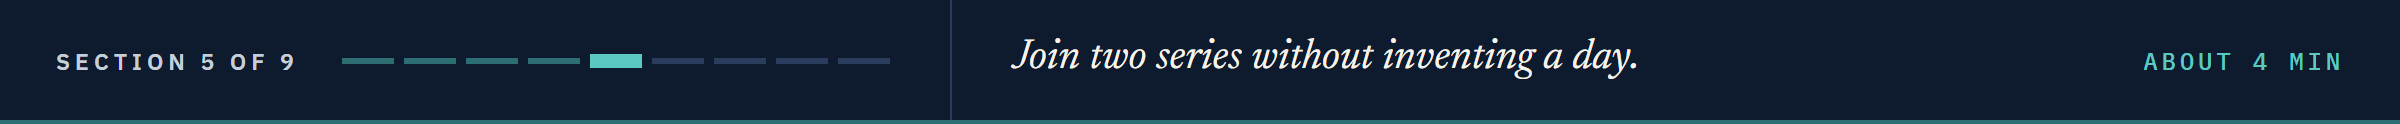

## 3.5 Joining Two Series: `align`

Course 1's Combining and Loading drew what `merge` keeps with `how=`.
`align` joins dated series the same way, on their dates, inner or outer.

**Predict 3**

Q. Join the file's 10 Yr with the parsed sample, which still holds its dot as `NaN`, outer. Labor Day:

A) is left out, since a `NaN` row is no date
B) is a row, `NaN` in both columns
C) is a row with Friday's value carried in

### Append `align`

Read the docstring first.
`pd.concat` with `axis=1`, as in Course 1's Combining and Loading, here takes a dict, `dict[str, pd.Series]`, whose keys name the columns.
`join=` picks inner or outer.

In [20]:
%%writefile -a marketdata.py


def align(series: dict[str, pd.Series], how: str = "inner") -> pd.DataFrame:
    """Put several dated series side by side, one column each, joined on date.

    Units: each column keeps its own units. Convention: how="inner" keeps the dates every series has;
    how="outer" keeps every date any series has and leaves NaN where a series has no row. Nothing is filled.
    Raises ValueError for any other `how`, or for a series whose index is not unique ascending dates.
    """
    # stop on a join the course does not use
    if how not in ("inner", "outer"):
        raise ValueError(f"how must be 'inner' or 'outer', not {how!r}")
    for name, values in series.items():
        _check_index(values.index, name)
    # one column per series, named by its key
    frame = pd.concat(series, axis=1, join=how)
    # an outer join can mix the order of dates, so sort them
    frame = frame.sort_index()
    frame.index.name = "date"
    return frame

Appending to marketdata.py


### Labor Day, Outer

In [21]:
# reload, then join the file's 10 Yr and the sample, outer
importlib.reload(md)
both = md.align({'file': file_span, 'fred': sample}, how='outer')
print(len(both), 'rows')
both.loc['2026-09-03':'2026-09-09']

43 rows


,file,fred
date,,
2026-09-03,4.77,4.77
2026-09-04,4.78,4.78
2026-09-07,NaN,NaN
2026-09-08,4.80,4.80
2026-09-09,4.83,4.83


B: the dot row brings in a date the market never had, and neither column has a number for it.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">A date with no row</td><td align="left"><code>both.loc['2026-09-07', 'file']</code>: <code>NaN</code></td><td align="left"><code>=XLOOKUP(DATE(2026,9,7),A2:A2941,B2:B2941)</code></td><td align="left"><code>#N/A</code></td></tr>
<tr><td align="left">The next market day</td><td align="left"><code>both.loc['2026-09-08', 'file']</code></td><td align="left"><code>=XLOOKUP(DATE(2026,9,8),A2:A2941,B2:B2941)</code></td><td align="left">4.8</td></tr>
</table>
<br clear="left">

### Drop the Dot First

In [22]:
# the sample with its dot dropped, joined both ways
dropped_outer = md.align({'file': file_span, 'fred': sample.dropna()}, how='outer')
clean = md.align({'file': file_span, 'fred': sample.dropna()})
print(len(dropped_outer), 'rows outer,', len(clean), 'inner; the columns equal:',
      clean['file'].equals(clean['fred']))

42 rows outer, 42 inner; the columns equal: True


### Where Outer Earns Its Place

In [23]:
# the 4 Mo bill has yields only from 2022-10-19
four_month = treasury['4 Mo'].dropna()
inner = md.align({'4 Mo': four_month, 'ig_spread_bp': spreads['ig_spread_bp']})
outer = md.align({'4 Mo': four_month, 'ig_spread_bp': spreads['ig_spread_bp']}, how='outer')
print(len(inner), 'rows inner;', len(outer), 'outer, with', outer['4 Mo'].isna().sum(), 'NaN')

989 rows inner; 2940 outer, with 1951 NaN


Inner drops almost eight years of spreads; outer keeps them and leaves the bill's cells empty, as they were.

### Two Tests

In [24]:
%%writefile -a test_marketdata.py


def test_align_inner_keeps_common_dates():
    dates = pd.to_datetime(["2026-09-03", "2026-09-04", "2026-09-08"])
    ten = pd.Series([5.20, 5.22, 5.25], index=dates)
    spread = pd.Series([98.0, 98.4], index=dates[[0, 2]])
    inner = md.align({"10 Yr": ten, "ig_spread_bp": spread})
    assert list(inner.index) == list(dates[[0, 2]])
    assert list(inner.columns) == ["10 Yr", "ig_spread_bp"]
    # an outer join keeps every date and leaves the gap empty, never filled
    outer = md.align({"10 Yr": ten, "ig_spread_bp": spread}, how="outer")
    assert len(outer) == 3 and math.isnan(outer.loc["2026-09-04", "ig_spread_bp"])


def test_align_rejects_unknown_how():
    ten = pd.Series([5.20], index=pd.to_datetime(["2026-09-03"]))
    with pytest.raises(ValueError):
        md.align({"10 Yr": ten}, how="left")

Appending to test_marketdata.py


**`align` keeps the common dates or every date and fills nothing: an outer join's `NaN` is honest, and a dot row brings in a date the market never had unless it is dropped first.**

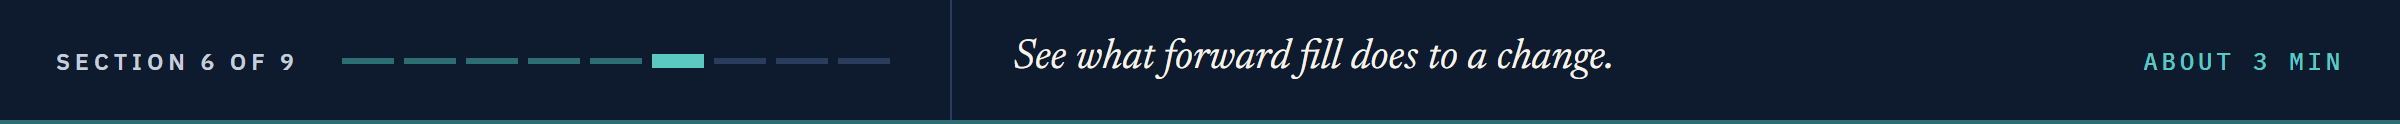

## 3.6 Forward Fill, for Display Only

`.ffill()` fills forward: each `NaN` takes the last value above it.

### Labor Day, Filled

In [25]:
# the outer join's file column, filled; changes in bp as in notebook 02
filled = both['file'].ffill()
change_rows = file_span.diff() * 100
change_filled = filled.diff() * 100
pd.DataFrame({'filled': filled, 'change, market rows': change_rows,
              'change, filled': change_filled}).loc['2026-09-03':'2026-09-09'].round(2)

,filled,"change, market rows","change, filled"
date,,,
2026-09-03,4.77,-2.0,-2.0
2026-09-04,4.78,1.0,1.0
2026-09-07,4.78,NaN,0.0
2026-09-08,4.80,2.0,2.0
2026-09-09,4.83,3.0,3.0


Filled, Labor Day takes Friday's 4.78 and a change of 0.0 bp on a day with no market.
Tuesday shows 2 bp either way: on market rows it is the change from Friday.

**Excel side by side.** T2:T4 hold Friday's 4.78, an empty Labor Day, and Tuesday's 4.8; U2 is `=T2`.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Fill forward</td><td align="left"><code>both['file'].ffill()</code></td><td align="left"><code>=IF(T3="",U2,T3)</code></td><td align="left">4.78</td></tr>
<tr><td align="left">Labor Day's change</td><td align="left"><code>filled.diff() * 100</code></td><td align="left"><code>=(U3-U2)*100</code></td><td align="left">0</td></tr>
<tr><td align="left">Tuesday's change</td><td align="left"><code>filled.diff() * 100</code></td><td align="left"><code>=(U4-U3)*100</code></td><td align="left">1.9999999999999574, as Python's before <code>.round(2)</code></td></tr>
</table>
<br clear="left">

### Draw Both

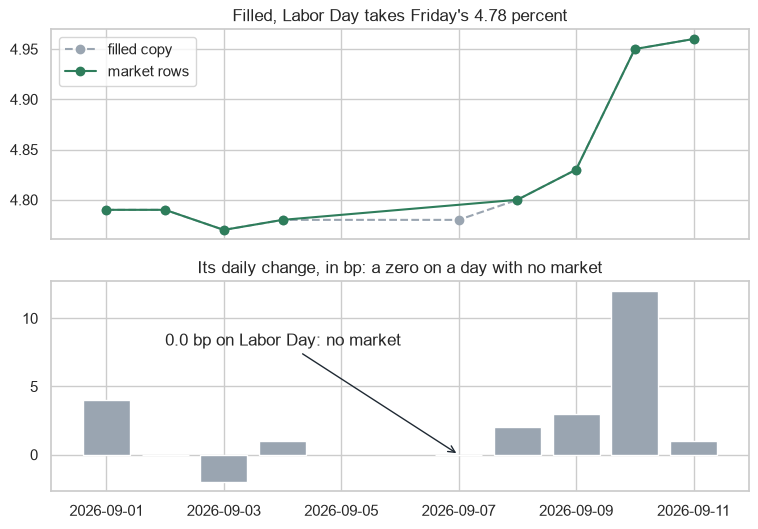

In [26]:
# the filled copy dashed under the market rows; below, the filled copy's daily changes
week = filled.loc['2026-09-01':'2026-09-11']
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(week.index, week, linestyle='--', marker='o', color='#9AA5B1', label='filled copy')
axes[0].plot(file_span.loc['2026-09-01':'2026-09-11'], marker='o', label='market rows')
axes[0].set_title("Filled, Labor Day takes Friday's 4.78 percent")
axes[0].legend()
axes[1].bar(week.index, change_filled.loc[week.index], color='#9AA5B1')
axes[1].annotate('0.0 bp on Labor Day: no market', xy=(pd.Timestamp('2026-09-07'), 0),
                 xytext=(pd.Timestamp('2026-09-02'), 8),
                 arrowprops={'arrowstyle': '->', 'color': '#1F2933'})
axes[1].set_title('Its daily change, in bp: a zero on a day with no market')
plt.show()

### Over the Whole Sample

In [27]:
# every change in the sample's span, market rows against the filled copy
for name, changes in [('market rows', change_rows), ('filled', change_filled)]:
    print(f'{name}: {changes.count()} changes, {(changes == 0).sum()} of them 0,',
          f'standard deviation {changes.std():.3f} bp')

market rows: 41 changes, 3 of them 0, standard deviation 4.909 bp
filled: 42 changes, 4 of them 0, standard deviation 4.854 bp


One filled day adds a zero and pulls the standard deviation down.

**Forward fill invents a zero change on a day with no market: fill a displayed copy only, never before a change, a window, or a join that feeds a number.**

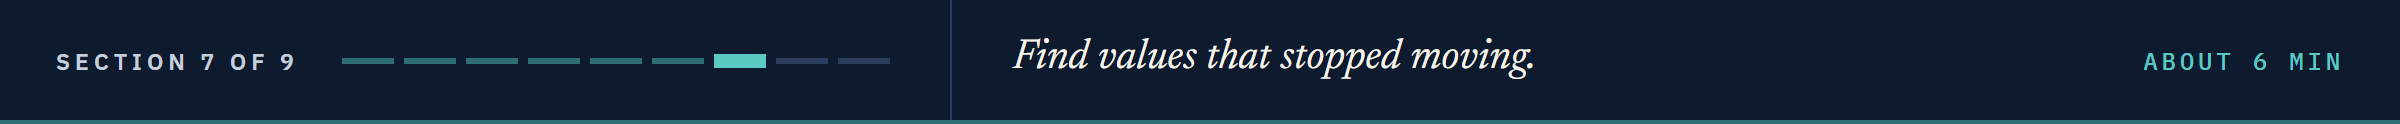

## 3.7 Stale Values: `stale_runs`

A gap is a day with no value.
A stale value is a row that is there and stopped moving: a feed that froze, a quote nobody updated.

### A Run, Counted by Hand

`.shift()` moves each value down one row, and the first row gets `NaN`.

In [28]:
# the test's seven values, on row numbers; each beside the value one row up
hand = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2])
steps = pd.DataFrame({'value': hand, 'before': hand.shift()})
steps['differs'] = steps['value'] != steps['before']
# cumsum, as Course 1's np.cumsum: a running total, each True counted as 1
steps['run'] = steps['differs'].cumsum()
steps

,value,before,differs,run
0,98.1,NaN,True,1
1,98.4,98.1,True,2
2,98.4,98.4,False,2
3,98.4,98.4,False,2
4,98.4,98.4,False,2
5,98.2,98.4,True,3
6,98.2,98.2,False,3


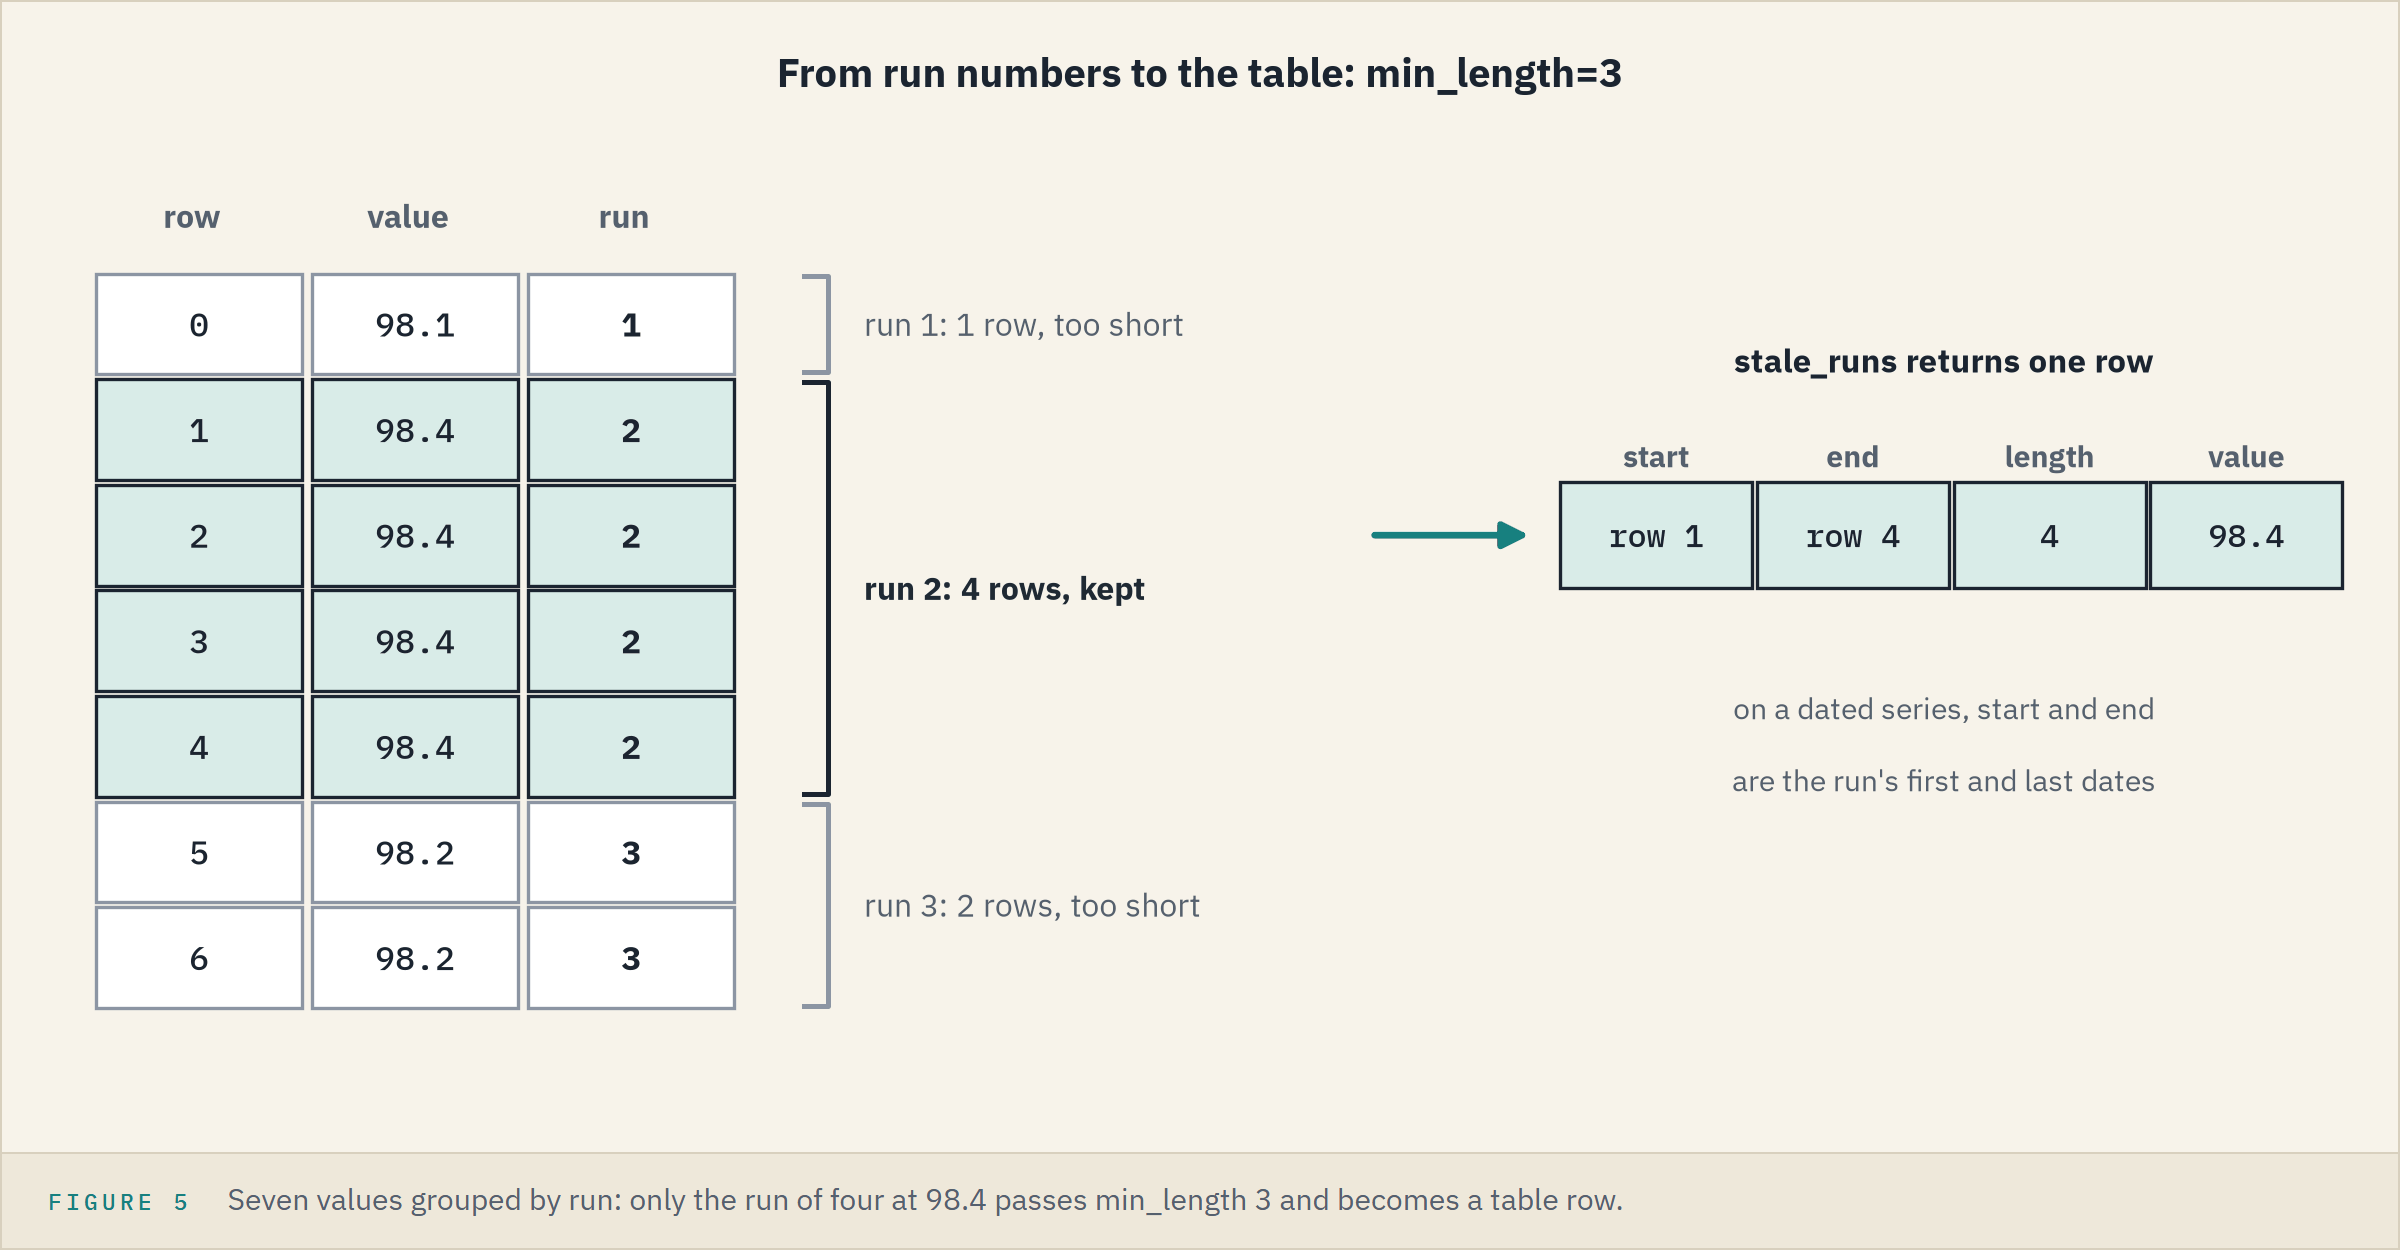

A new run starts wherever a value differs from the one before.

### Append `stale_runs`

It refuses `NaN`: a gap is not a run, so drop it first.
`for _, run in series.groupby(run_id)` visits each run in turn; `_` sets the run number aside, as in Course 2.
`pd.DataFrame(runs, columns=...)` names the columns even when no run is found.

In [29]:
%%writefile -a marketdata.py


def stale_runs(series: pd.Series, min_length: int = 3) -> pd.DataFrame:
    """Runs of the same value repeated on consecutive observations: a sign of a value that stopped updating.

    Units: `value` has the series' units, `length` counts observations. Convention: consecutive means
    consecutive rows, whatever the calendar gap. One row per run of at least `min_length` identical values,
    with columns start, end, length, value.
    Raises ValueError if min_length is below 2, the series has missing values (drop them first), or its index
    is not unique ascending dates.
    """
    _check_index(series.index, "series")
    if min_length < 2:
        raise ValueError(f"min_length must be at least 2, not {min_length}")
    if series.isna().any():
        raise ValueError(f"series has {series.isna().sum()} missing values; drop them first with .dropna()")
    # a new run starts wherever the value differs from the row before
    run_id = (series != series.shift()).cumsum()
    runs = []
    for _, run in series.groupby(run_id):
        # keep runs long enough to report
        if len(run) >= min_length:
            runs.append({"start": run.index[0], "end": run.index[-1], "length": len(run), "value": run.iloc[0]})
    return pd.DataFrame(runs, columns=["start", "end", "length", "value"])

Appending to marketdata.py


### Runs of Three in the Spreads

In [30]:
# reload, then runs of three or more in both synthetic spreads
importlib.reload(md)
ig, hy = spreads['ig_spread_bp'], spreads['hy_spread_bp']
ig_runs = md.stale_runs(ig)
print(len(ig_runs), 'IG runs of 3 or more;', len(md.stale_runs(hy)), 'HY')
ig_runs

4 IG runs of 3 or more; 0 HY


,start,end,length,value
0,2015-02-13,2015-02-18,3,84.7
1,2021-12-08,2021-12-10,3,81.3
2,2024-02-14,2024-02-16,3,107.2
3,2025-11-21,2025-11-25,3,92.2


**Excel side by side.** D4 holds `=AND(C4=C3,C3=C2)`, filled down to D2941: TRUE where a spread equals the two rows above it.

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Runs of 3 or more</td><td align="left"><code>len(md.stale_runs(ig))</code></td><td align="left"><code>=COUNTIF(D4:D2941,TRUE)</code></td><td align="left">4</td></tr>
<tr><td align="left">Where</td><td align="left"><code>ig_runs['end']</code></td><td align="left">the rows showing TRUE</td><td align="left">2015-02-18, 2021-12-10, 2024-02-16, 2025-11-25</td></tr>
</table>
<br clear="left">

### The First Run, Drawn

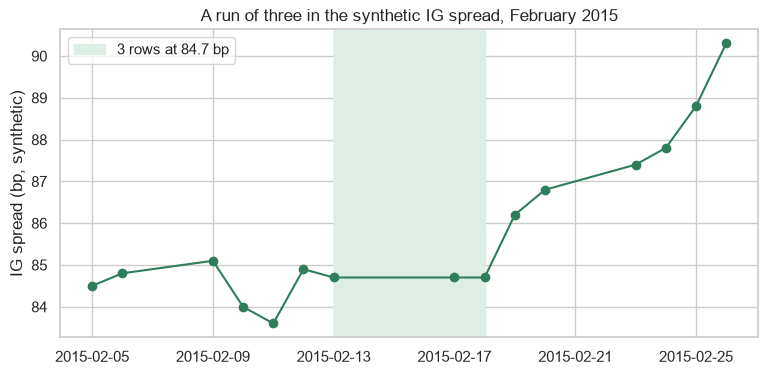

In [31]:
# the first IG run and three weeks around it
run = ig_runs.loc[0]
weeks = ig.loc['2015-02-05':'2015-02-26']
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weeks.index, weeks, marker='o')
# axvspan shades the band between two dates
ax.axvspan(run['start'], run['end'], color='#DDEFE5',
           label=f"{run['length']} rows at {run['value']} bp")
ax.set_title('A run of three in the synthetic IG spread, February 2015')
ax.set_ylabel('IG spread (bp, synthetic)')
ax.legend()
plt.show()

Three rows over six calendar days: Monday 16 February had no row, and a run counts rows.

### Longer, Shorter, and a Real Yield

In [32]:
# runs of 5 or more and of 2 or more; then the 2 Yr yield, which has a value on every row
for length in [5, 2]:
    print(f'runs of {length} or more: IG {len(md.stale_runs(ig, length))},',
          f'HY {len(md.stale_runs(hy, length))}')
two_year_runs = md.stale_runs(treasury['2 Yr'])
print(len(two_year_runs), '2 Yr runs of 3 or more; the longest:')
two_year_runs[two_year_runs['length'] == two_year_runs['length'].max()]

runs of 5 or more: IG 0, HY 0
runs of 2 or more: IG 107, HY 29
84 2 Yr runs of 3 or more; the longest:


,start,end,length,value
54,2020-12-16,2020-12-28,8,0.13
65,2021-05-10,2021-05-19,8,0.16


`stale_runs` works on any series without gaps, `True` and `False` included: there it reports runs of each, and `value` says which.

### The Last Test

Its dates are a hand series: any seven weekdays do.

In [33]:
%%writefile -a test_marketdata.py


def test_stale_runs_finds_a_run():
    dates = pd.bdate_range("2026-09-01", periods=7)
    values = pd.Series([98.1, 98.4, 98.4, 98.4, 98.4, 98.2, 98.2], index=dates)
    runs = md.stale_runs(values, min_length=3)
    # one run of four, from the second row to the fifth; the pair at the end is too short
    assert len(runs) == 1
    assert runs.loc[0, "start"] == dates[1] and runs.loc[0, "end"] == dates[4]
    assert runs.loc[0, "length"] == 4 and runs.loc[0, "value"] == 98.4

Appending to test_marketdata.py


### Run pytest

In [34]:
import subprocess
import sys

# python -m pytest -q on the test file, with this notebook's own Python and no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', 'test_marketdata.py']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............                                                            [100%]
13 passed in 0.50s



**A run is a reason to look, not a verdict: no run of five or more in the spreads, and a two-decimal yield sat still for eight market days.**

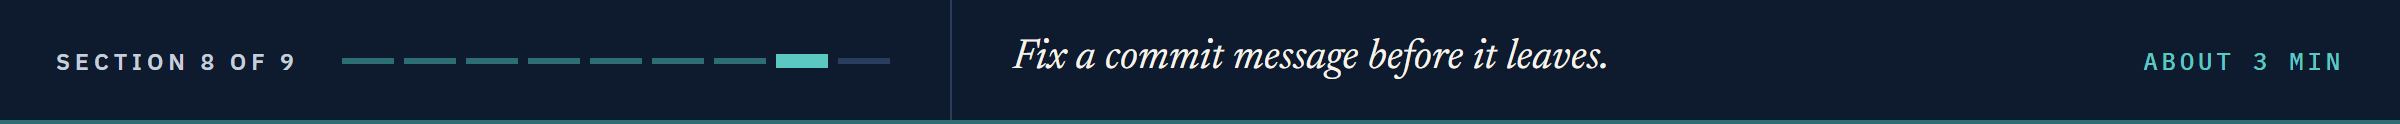

## 3.8 Fix the Message Before Anything Builds on It

The note's last ask: a commit under a message we can search for.

### What Changed

In [35]:
!git -C "{work}" status --short
!git -C "{work}" diff --stat

 M marketdata.py
 M test_marketdata.py
 marketdata.py      | 73 ++++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_marketdata.py | 36 +++++++++++++++++++++++++++
 2 files changed, 109 insertions(+)


### Commit

In [36]:
!git -C "{work}" add marketdata.py test_marketdata.py
!git -C "{work}" commit -q -m "Notebook 03: missing_weekdays, align, and stale_run"
!git -C "{work}" log --oneline

8a97867 Notebook 03: missing_weekdays, align, and stale_run
ceea769 Notebook 02: fred_params, parse_fred_observations, and fred_series
a28686d Notebook 01: get_secret, a .gitignore, and .env.example


The subject has a slip: `stale_run`, one letter short, and a search for `stale_runs` would miss it.

### Amend the Message

`git commit --amend` swaps the last commit for a new one with the same files; `-m` gives it the right message.

In [37]:
!git -C "{work}" commit --amend -q -m "Notebook 03: missing_weekdays, align, and stale_runs"
!git -C "{work}" log --oneline

a439502 Notebook 03: missing_weekdays, align, and stale_runs
ceea769 Notebook 02: fred_params, parse_fred_observations, and fred_series
a28686d Notebook 01: get_secret, a .gitignore, and .env.example


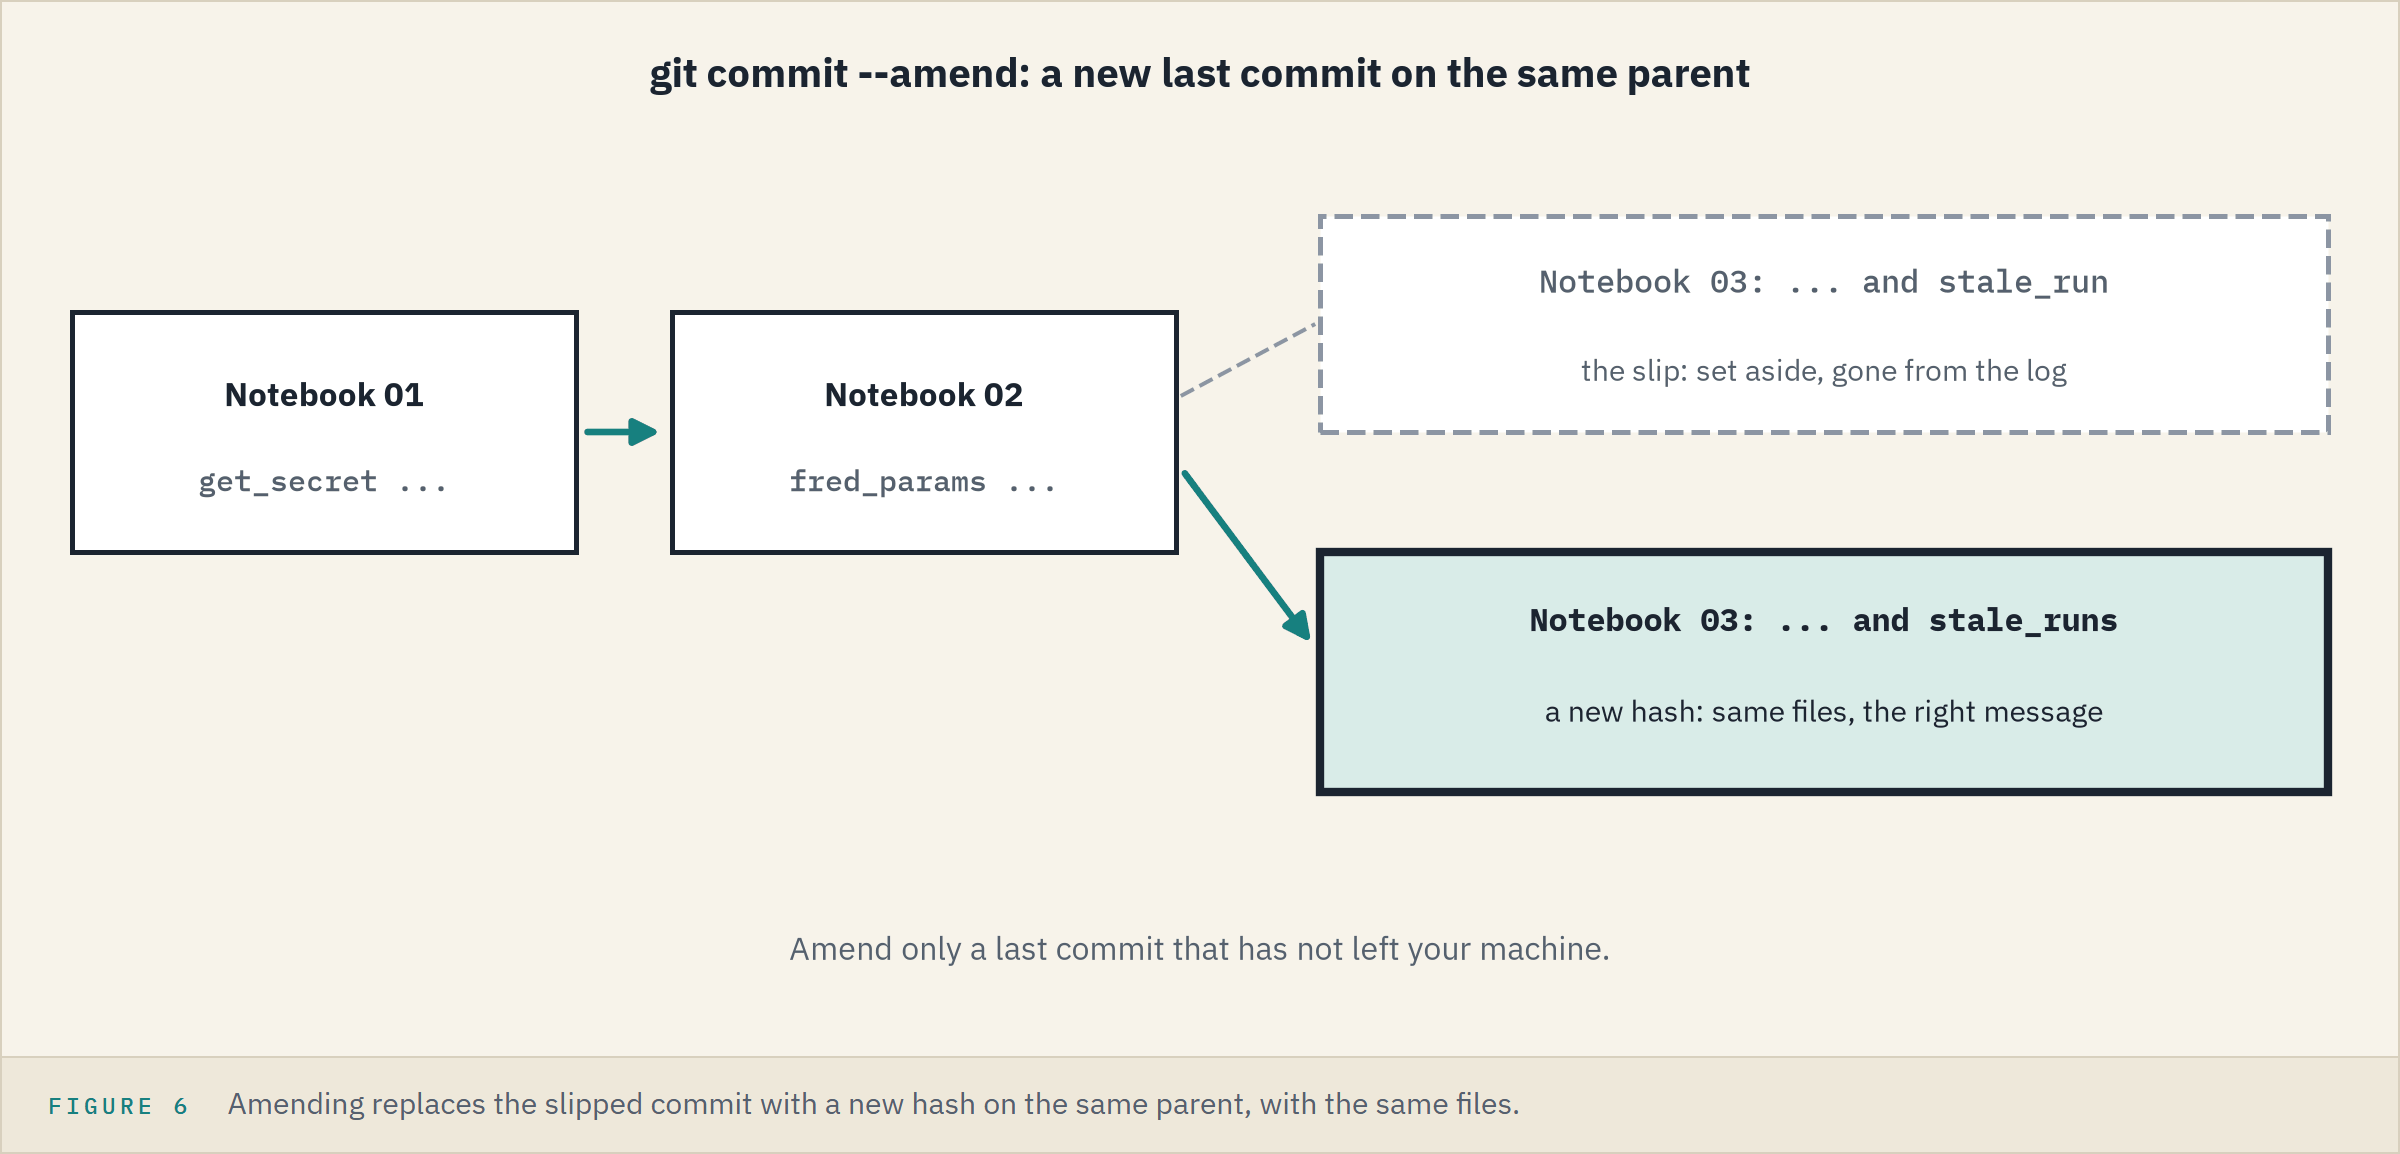

Still three commits; the top one has a new hash.
Amend only a last commit that has not left your machine: once pushed, fix it with a new commit.

**`--amend` replaces the last commit: the same files, the right message, and the slip gone from the log.**

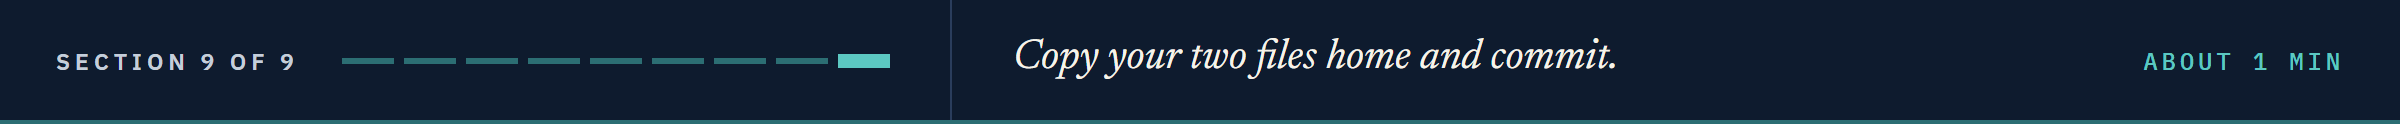

## Bring It Home

Copy the work folder's two files into `my_bondmath`, test them, and commit.
The copy replaces your two files, so anything of your own must be in the work folder first.
In a PowerShell terminal in VS Code, with the course's `.venv` active:

```powershell
# the work folder: use the name your setup cell printed
$work = "$env:TEMP\pfi_course3_03_k4w7q2xr"
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$work\marketdata.py", "$work\test_marketdata.py" .
python -m pytest -q test_marketdata.py
git status --short
git diff --stat
git add marketdata.py test_marketdata.py
git commit -m "Notebook 03: missing_weekdays, align, and stale_runs"
```

pytest shows `13 passed`, and the DGS10 sample the tests read is there since notebook 02.
A slip in your own message is fixed with `git commit --amend -m` while the commit has not left your machine.
In Colab, download the two files from the work folder under `/tmp` instead.
The work folder stays in your temp folder; the system clears it in time.

## You Can Now

By the end of this notebook, you can:

* Count calendar days, weekdays and market days, and say which one a calculation runs on.
* Find the weekdays a file skips with `missing_weekdays`, and give Excel the same list.
* Show where pandas' federal holiday calendar disagrees with the file, both ways.
* Check that FRED's dots fall on the file's missing weekdays.
* Join series on their dates with `align`, inner or outer, filling nothing.
* Say what forward fill does to a change, and keep it for display.
* Find values that stopped moving with `stale_runs`, and fix a commit message with `--amend`.

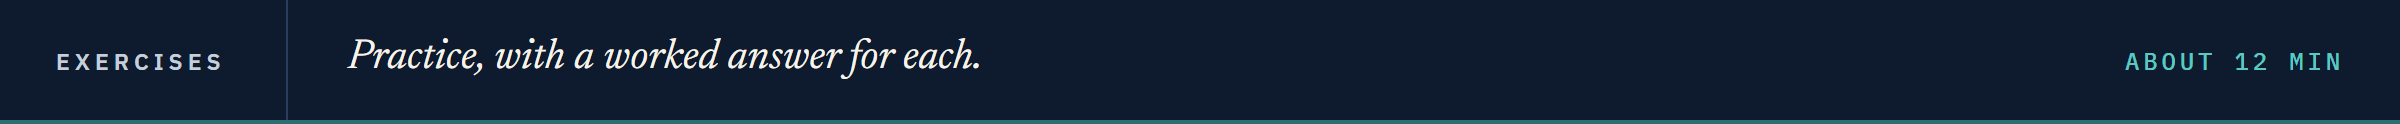

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.
Run the next two cells first: `check`, and the files.

In [38]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [39]:
# the two files, the missing weekdays, and pandas' federal holidays
treasury = pd.read_csv('treasury_par_yields.csv', parse_dates=['date'], index_col='date',
                       float_precision='round_trip')
spreads = pd.read_csv('course3_synthetic_spreads.csv', parse_dates=['date'], index_col='date',
                      float_precision='round_trip')
missing = md.missing_weekdays(treasury.index)
federal = USFederalHolidayCalendar().holidays(treasury.index[0], treasury.index[-1],
                                              return_name=True)

### Exercise 1

Q. How many weekdays did the file skip in 2020, and in 2025? Store the two counts as a list in **ex1_counts**. Then list 2025's skipped weekdays that are not federal holidays, as `'YYYY-MM-DD'` text, in **ex1_not_federal**.

In [40]:
ex1_counts = ...
ex1_not_federal = ...

In [41]:
check('Exercise 1 the counts', ex1_counts, [11, 12])
check('Exercise 1 not federal in 2025', ex1_not_federal, ['2025-04-18'])

Exercise 1 the counts: not attempted yet
Exercise 1 not federal in 2025: not attempted yet


### Exercise 2

Q. Align the 2026 `5 Yr` yields with the high yield spread, `spreads['hy_spread_bp']`. Store the rows of the inner join in **ex2_inner_rows**, and the number of `NaN` in the outer join's `5 Yr` column in **ex2_outer_missing**.

In [42]:
ex2_inner_rows = ...
ex2_outer_missing = ...

In [43]:
check('Exercise 2 inner rows', ex2_inner_rows, 190)
check('Exercise 2 outer NaN', ex2_outer_missing, 2750)

Exercise 2 inner rows: not attempted yet
Exercise 2 outer NaN: not attempted yet


### Exercise 3

Q. Add `market_days_between(index, start, end)`, docstring first: the number of market days from `start` to `end`, both included, where the market days are the dates of `index`. Check the index with `_check_index`, and raise `ValueError` if `start` is after `end`. Add `test_market_days_between_counts_rows` on a hand index around Labor Day 2026, with a `pytest.raises` check. Run pytest, reload, and store `md.market_days_between(treasury.index, '2026-09-01', '2026-09-30')` in **ex3_september**.

In [44]:
%%writefile -a marketdata.py


# Exercise 3: write market_days_between(index, start, end) below this line

Appending to marketdata.py


In [45]:
%%writefile -a test_marketdata.py


# Exercise 3: write test_market_days_between_counts_rows() below this line

Appending to test_marketdata.py


In [46]:
# run pytest as in the lesson, reload the module, then call your function
ex3_september = ...

In [47]:
check('Exercise 3 market days in September 2026', ex3_september, 21)

Exercise 3 market days in September 2026: not attempted yet


### Exercise 4: AI check

You gave an assistant the docstring below as the prompt; the function came back, written for this course in the style of an assistant's answer, and holds one bug.

In [48]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
from pandas.tseries.offsets import CustomBusinessDay


def closed_days(index):
    """The weekdays from the first date to the last on which the market had no row.

    Units: dates. Convention: the data's own dates are the market calendar. A weekday with a row
    was open, a weekday without one was closed, whatever the reason. No holiday calendar
    decides it.
    """
    # business days: Monday to Friday, less a calendar's holidays
    business_days = CustomBusinessDay(calendar=USFederalHolidayCalendar())
    # date_range with freq= steps from date to date by that rule
    open_days = pd.date_range(index[0], index[-1], freq=business_days)
    # every weekday that is not a business day was a closed day
    return pd.bdate_range(index[0], index[-1]).difference(open_days)

Q. How many dates does it return for the file, and is Good Friday 2025 among them?

In [49]:
print(len(closed_days(treasury.index)), 'dates; 2025-04-18 among them:',
      pd.Timestamp('2025-04-18') in closed_days(treasury.index))

121 dates; 2025-04-18 among them: False


Run the test under it.

In [50]:
# the test, written from the docstring before the code is trusted
closed = closed_days(treasury.index)
assert pd.Timestamp('2025-04-18') in closed, 'a weekday with no row is missing'
assert not closed.isin(treasury.index).any(), 'a day with a row is reported closed'
assert closed.equals(missing), "the result is not the file's own calendar"
print("closed_days is the file's own calendar")

AssertionError: a weekday with no row is missing

Q. Fix the function, then run it and the test again until the test passes. Store the number of dates it returns for `treasury.index` in **ex4_count**, and how many of them have a row in the file, `closed_days(treasury.index).isin(treasury.index).sum()`, in **ex4_with_rows**.

In [51]:
ex4_count = ...
ex4_with_rows = ...

In [52]:
check('Exercise 4 closed days', ex4_count, 126)
check('Exercise 4 closed days with a row', ex4_with_rows, 0)

Exercise 4 closed days: not attempted yet
Exercise 4 closed days with a row: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">The weekdays the file skips</td><td align="left"><code>missing_weekdays</code>: 126, and as Excel's list the seven of 2026 give its 190 rows</td></tr>
<tr><td align="left">The holiday calendar</td><td align="left">121 federal holidays: it misses 9 closures and closes 4 market days</td></tr>
<tr><td align="left">FRED's dots</td><td align="left">The same days, tied on the sample and live</td></tr>
<tr><td align="left">Side by side, no day invented</td><td align="left"><code>align</code>, inner or outer, nothing filled</td></tr>
<tr><td align="left">Forward fill</td><td align="left">A zero change on Labor Day: display only</td></tr>
<tr><td align="left">Values that stopped</td><td align="left"><code>stale_runs</code>: 4 IG runs of three, none of five or more</td></tr>
<tr><td align="left">Three functions, committed</td><td align="left"><code>13 passed</code>, the message amended</td></tr>
</table>
<br clear="left">

Be proud: from today every series in this course runs on the market's own days.

Next: Resampling and the As-Of Value (notebook 04) asks which of these days stands for a week or a month.

[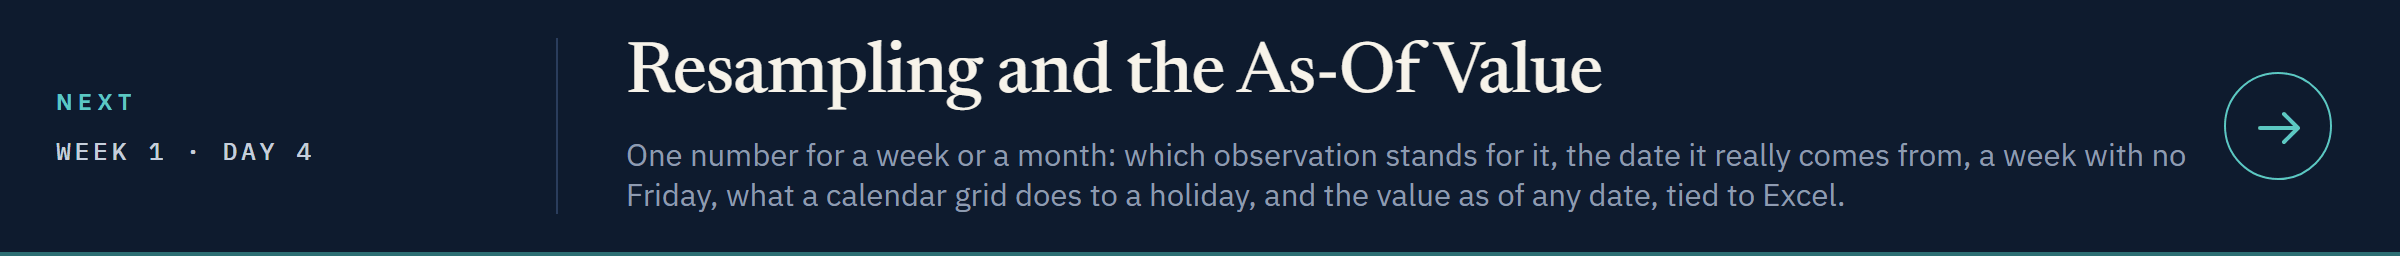](../day4/04_resampling_and_the_as_of_value.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course03_market_data/week1/day4/04_resampling_and_the_as_of_value.ipynb)